# Stage 4.2A — PAY + Categorical Raw Risk Diagnostics

## Objective and strict boundary

This Phase generates **Train-only raw-state/category risk evidence** for the Architect/user Human Checkpoint. It does not create final bins.

Authorized diagnostic scope is exactly 12 variables:

- PAY_0, PAY_2, PAY_3, PAY_4, PAY_5, PAY_6
- delinquent_months, max_delinquency, severe_delinquent_months
- SEX, EDUCATION_GROUP, MARRIAGE_GROUP

No PAY state, delinquency value, or category is merged, replaced, smoothed, ranked, retained, or dropped. No continuous Stage 4.3 predictor is analyzed. No model, KFold, AUC, KS, or Holdout Test target analysis is performed.

In [1]:
from pathlib import Path
import hashlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 190)
pd.set_option("display.max_rows", 120)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")

TARGET = "default.payment.next.month"
ID_COL = "ID"
RANDOM_STATE = 42
TEST_SIZE = 0.20
EXPECTED_TRAIN_HASH = "bcb37af63ae7005df78e6140837594b5d650d27148b46b5d51354430ad958857"
EXPECTED_TEST_HASH = "d6748249f9f9fb2855746e0ed980b5013047267104090a14aa8138a700fe6f0f"

PAY_VARIABLES = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
DELINQUENCY_VARIABLES = ["delinquent_months", "max_delinquency", "severe_delinquent_months"]
CATEGORICAL_VARIABLES = ["SEX", "EDUCATION_GROUP", "MARRIAGE_GROUP"]
SCOPE_VARIABLES = PAY_VARIABLES + DELINQUENCY_VARIABLES + CATEGORICAL_VARIABLES
assert len(SCOPE_VARIABLES) == 12 and len(set(SCOPE_VARIABLES)) == 12

EDUCATION_MAP = {
    1: "Graduate School", 2: "University", 3: "High School",
    0: "Other / Unknown", 4: "Other / Unknown",
    5: "Other / Unknown", 6: "Other / Unknown",
}
MARRIAGE_MAP = {
    1: "Married", 2: "Single", 0: "Other / Unknown", 3: "Other / Unknown",
}
EDUCATION_ORDER = ["Graduate School", "University", "High School", "Other / Unknown"]
MARRIAGE_ORDER = ["Married", "Single", "Other / Unknown"]

def locate_project_root():
    start = Path.cwd().resolve()
    for candidate in (start, *start.parents):
        if (candidate / "data/raw/UCI_Credit_Card.csv").is_file():
            return candidate
    raise FileNotFoundError("Formal raw CSV not found.")

def stable_id_set_hash(values):
    canonical = "\n".join(str(int(value)) for value in sorted(values))
    return hashlib.sha256(canonical.encode("utf-8")).hexdigest()

project_root = locate_project_root()
data_path = project_root / "data/raw/UCI_Credit_Card.csv"
print("Python executable:", sys.executable)
print("Python version:", sys.version.split()[0])
print("Project root:", project_root)
print("Authorized diagnostic variables:", len(SCOPE_VARIABLES))

Matplotlib is building the font cache; this may take a moment.


Python executable: /Users/yu/2.工作/Risk Analysis Project/.venv/bin/python
Python version: 3.9.6
Project root: /Users/yu/2.工作/Risk Analysis Project
Authorized diagnostic variables: 12


## 1. Raw load, locked split replay, and Holdout Test sealing

The formal raw CSV is loaded only to reproduce the locked 80/20 stratified split. Holdout Test is used solely for row-count, ID overlap/coverage, and stable ID-set hash assertions. No Test target or predictor statistic is displayed. After those assertions, the Test frame and full raw frame are deleted from live state.

In [2]:
raw_df = pd.read_csv(data_path)
assert raw_df.shape == (30000, 25)
assert raw_df[ID_COL].is_unique
assert raw_df.isna().sum().sum() == 0

train_raw, sealed_test = train_test_split(
    raw_df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=raw_df[TARGET],
)

train_ids = set(train_raw[ID_COL].astype(int))
test_ids = set(sealed_test[ID_COL].astype(int))
full_ids = set(raw_df[ID_COL].astype(int))
train_id_hash = stable_id_set_hash(train_ids)
test_id_hash = stable_id_set_hash(test_ids)

assert len(raw_df) == 30000
assert len(train_raw) == 24000
assert len(sealed_test) == 6000
assert train_ids.isdisjoint(test_ids)
assert train_ids | test_ids == full_ids
assert len(train_ids) + len(test_ids) == len(full_ids) == 30000
assert train_id_hash == EXPECTED_TRAIN_HASH
assert test_id_hash == EXPECTED_TEST_HASH

split_evidence = pd.DataFrame({"Actual": [
    "train_test_split", "80% / 20%", RANDOM_STATE,
    len(raw_df), len(train_raw), len(sealed_test), len(train_ids & test_ids),
    train_ids | test_ids == full_ids, train_id_hash, test_id_hash,
]}, index=[
    "Method", "Ratio", "random_state", "Raw rows", "Train rows", "Test rows",
    "ID overlap", "Full ID coverage", "Train ID SHA-256", "Test ID SHA-256",
])
display(split_evidence)

train_original = train_raw.copy(deep=True)
del sealed_test, raw_df, test_ids, full_ids
TEST_SEAL_STATUS = "SEALED — technical row/ID/hash assertions completed; Test frame deleted"
print(TEST_SEAL_STATUS)

,Actual
Method,train_test_split
Ratio,80% / 20%
random_state,42
Raw rows,30000
Train rows,24000
Test rows,6000
ID overlap,0
Full ID coverage,True
Train ID SHA-256,bcb37af63ae7005df78e6140837594b5d650d27148b46b...
Test ID SHA-256,d6748249f9f9fb2855746e0ed980b5013047267104090a...


SEALED — technical row/ID/hash assertions completed; Test frame deleted


## 2. Reproduce only the required frozen Stage 3 Train features

The exact Stage 3.3 definitions are replayed on Train only:

- EDUCATION_GROUP and MARRIAGE_GROUP use their frozen mappings.
- delinquent_months counts six PAY values greater than 0.
- max_delinquency is the maximum after calculation-only flooring at 0.
- severe_delinquent_months counts six PAY values at least 2.

Raw PAY values, Train rows, ID alignment, and target remain unchanged. Utilization and all other Stage 4.3 variables are not reproduced or analyzed here.

In [3]:
train_work = train_raw.copy(deep=True)
raw_pay_before = train_work[PAY_VARIABLES].copy(deep=True)

train_work["EDUCATION_GROUP"] = train_work["EDUCATION"].map(EDUCATION_MAP)
train_work["MARRIAGE_GROUP"] = train_work["MARRIAGE"].map(MARRIAGE_MAP)
pay_matrix = train_work[PAY_VARIABLES]
train_work["delinquent_months"] = (pay_matrix > 0).sum(axis=1).astype("int64")
train_work["max_delinquency"] = pay_matrix.clip(lower=0).max(axis=1).astype("int64")
train_work["severe_delinquent_months"] = (pay_matrix >= 2).sum(axis=1).astype("int64")

recalc_delinquent = (train_original[PAY_VARIABLES] > 0).sum(axis=1).astype("int64")
recalc_max = train_original[PAY_VARIABLES].clip(lower=0).max(axis=1).astype("int64")
recalc_severe = (train_original[PAY_VARIABLES] >= 2).sum(axis=1).astype("int64")

assert len(train_work) == len(train_original) == 24000
assert train_work.index.equals(train_original.index)
assert train_work[ID_COL].equals(train_original[ID_COL])
assert train_work[TARGET].equals(train_original[TARGET])
assert train_work[ID_COL].is_unique
assert set(train_work[ID_COL].astype(int)) == train_ids
assert train_work.duplicated(subset=[ID_COL]).sum() == 0
pd.testing.assert_frame_equal(train_work[PAY_VARIABLES], raw_pay_before, check_exact=True)
assert train_work["delinquent_months"].equals(recalc_delinquent)
assert train_work["max_delinquency"].equals(recalc_max)
assert train_work["severe_delinquent_months"].equals(recalc_severe)
assert train_work[["EDUCATION_GROUP", "MARRIAGE_GROUP"]].notna().all().all()
assert set(train_work["EDUCATION_GROUP"].unique()) == set(EDUCATION_ORDER)
assert set(train_work["MARRIAGE_GROUP"].unique()) == set(MARRIAGE_ORDER)
assert train_work["delinquent_months"].between(0, 6).all()
assert train_work["severe_delinquent_months"].between(0, 6).all()
assert (train_work["severe_delinquent_months"] <= train_work["delinquent_months"]).all()
assert (train_work["max_delinquency"] >= 0).all()
assert train_work[SCOPE_VARIABLES].isna().sum().sum() == 0

feature_reproduction = pd.DataFrame({"Result": [
    "PASS — 24,000 rows; ID/index/target unchanged",
    "PASS — six raw PAY columns unchanged",
    "PASS — frozen category mappings exact",
    "PASS — three delinquency formulas independently reproduced",
    "PASS — no missing values in the 12 diagnostic variables",
    "PASS — no Test transformation and no Stage 4.3 feature reproduction",
]}, index=[
    "Row/label integrity", "Raw PAY integrity", "Category mappings",
    "Delinquency formulas", "Diagnostic completeness", "Scope boundary",
])
display(feature_reproduction)

,Result
Row/label integrity,"PASS — 24,000 rows; ID/index/target unchanged"
Raw PAY integrity,PASS — six raw PAY columns unchanged
Category mappings,PASS — frozen category mappings exact
Delinquency formulas,PASS — three delinquency formulas independentl...
Diagnostic completeness,PASS — no missing values in the 12 diagnostic ...
Scope boundary,PASS — no Test transformation and no Stage 4.3...


## 3. Frozen Train-only WOE / IV diagnostic helper

The helper operates on one in-scope Train variable and the Train target. It preserves every observed raw state/category and performs no merging, replacement, relabeling, or smoothing.

Frozen direction:

- 0 = Good / Non-default
- 1 = Bad / Default
- WOE = ln(Dist Good / Dist Bad)
- positive WOE = relatively lower risk
- negative WOE = relatively higher risk

If Good or Bad is zero, the formal table retains the raw count and mathematically infinite WOE/IV contribution, and visibly flags the state for Human Checkpoint.

In [4]:
TRAIN_ROWS = len(train_work)
TOTAL_GOOD = int((train_work[TARGET] == 0).sum())
TOTAL_BAD = int((train_work[TARGET] == 1).sum())
assert TOTAL_GOOD + TOTAL_BAD == TRAIN_ROWS == 24000

diagnostic_tables = {}
raw_iv_totals = {}
figure_ids = []
diagnostic_notes = {}

def build_raw_diagnostic(variable, display_order=None):
    assert variable in SCOPE_VARIABLES
    grouped = (
        train_work.groupby(variable, dropna=False, observed=True)[TARGET]
        .agg(Count="size", Bad="sum")
    )
    grouped["Good"] = grouped["Count"] - grouped["Bad"]
    if display_order is not None:
        observed = list(grouped.index)
        assert set(observed) == set(display_order)
        grouped = grouped.loc[display_order]
    else:
        grouped = grouped.sort_index()

    table = grouped.reset_index().rename(columns={variable: "State / Category"})
    table["Percent of Train"] = table["Count"] / TRAIN_ROWS
    table["Default Rate"] = table["Bad"] / table["Count"]
    table["Dist Good"] = table["Good"] / TOTAL_GOOD
    table["Dist Bad"] = table["Bad"] / TOTAL_BAD
    with np.errstate(divide="ignore", invalid="ignore"):
        table["WOE"] = np.log(table["Dist Good"] / table["Dist Bad"])
        table["IV Contribution"] = (table["Dist Good"] - table["Dist Bad"]) * table["WOE"]
    table["Zero-event flag"] = np.select(
        [table["Good"] == 0, table["Bad"] == 0],
        ["Good = 0 — Human Checkpoint required", "Bad = 0 — Human Checkpoint required"],
        default="None",
    )
    table = table[[
        "State / Category", "Count", "Percent of Train", "Good", "Bad",
        "Default Rate", "Dist Good", "Dist Bad", "WOE", "IV Contribution", "Zero-event flag",
    ]]

    assert int(table["Count"].sum()) == TRAIN_ROWS
    assert int(table["Good"].sum()) == TOTAL_GOOD
    assert int(table["Bad"].sum()) == TOTAL_BAD
    assert (table["Count"] == table["Good"] + table["Bad"]).all()
    assert np.isclose(table["Percent of Train"].sum(), 1.0, atol=1e-12)
    assert np.isclose(table["Dist Good"].sum(), 1.0, atol=1e-12)
    assert np.isclose(table["Dist Bad"].sum(), 1.0, atol=1e-12)
    finite_rows = np.isfinite(table["WOE"])
    np.testing.assert_allclose(
        table.loc[finite_rows, "WOE"],
        np.log(table.loc[finite_rows, "Dist Good"] / table.loc[finite_rows, "Dist Bad"]),
        rtol=1e-12, atol=1e-12,
    )
    np.testing.assert_allclose(
        table.loc[finite_rows, "IV Contribution"],
        (table.loc[finite_rows, "Dist Good"] - table.loc[finite_rows, "Dist Bad"]) * table.loc[finite_rows, "WOE"],
        rtol=1e-12, atol=1e-12,
    )
    return table

def register_diagnostic(variable, table):
    assert variable not in diagnostic_tables
    diagnostic_tables[variable] = table.copy()
    raw_iv_totals[variable] = float(table["IV Contribution"].sum())
    smallest = table.loc[table["Count"].idxmin()]
    rate_min = table.loc[table["Default Rate"].idxmin()]
    rate_max = table.loc[table["Default Rate"].idxmax()]
    diagnostic_notes[variable] = (
        f"Observed {len(table)} raw states/categories; Default Rate spans "
        f"{rate_min['Default Rate']:.2%} to {rate_max['Default Rate']:.2%}; "
        f"smallest support is {smallest['State / Category']} with {int(smallest['Count']):,} rows "
        f"({smallest['Percent of Train']:.3%})."
    )

def render_default_support_figure(variable, table, figure_id):
    assert figure_id not in figure_ids
    labels = table["State / Category"].astype(str).tolist()
    x = np.arange(len(labels))
    fig, axes = plt.subplots(
        2, 1, figsize=(8.4, 5.2), sharex=True,
        gridspec_kw={"height_ratios": [2.0, 1.25]},
    )
    axes[0].bar(x, table["Default Rate"], color="#4472C4")
    axes[0].set_ylabel("Default Rate")
    axes[0].set_ylim(0, min(1.0, max(0.10, float(table["Default Rate"].max()) * 1.18)))
    axes[0].grid(axis="y", alpha=0.25)
    for index, value in enumerate(table["Default Rate"]):
        axes[0].text(index, value, f"{value:.1%}", ha="center", va="bottom", fontsize=8)

    axes[1].bar(x, table["Count"], color="#A5A5A5")
    axes[1].set_ylabel("Train Count")
    axes[1].set_xlabel("Observed raw state/value")
    axes[1].grid(axis="y", alpha=0.25)
    axes[1].set_xticks(x, labels, rotation=0)
    for index, value in enumerate(table["Count"]):
        axes[1].text(index, value, f"{int(value):,}", ha="center", va="bottom", fontsize=7)

    fig.suptitle(f"{figure_id} — {variable}: raw Default Rate and sample support", fontsize=12)
    fig.tight_layout()
    plt.show()
    plt.close(fig)
    figure_ids.append(figure_id)

print("Train totals used by every raw diagnostic — Good:", TOTAL_GOOD, "Bad:", TOTAL_BAD)
print("Helper policy: observed raw states only; no merge; no smoothing; no selection.")

Train totals used by every raw diagnostic — Good: 18691 Bad: 5309
Helper policy: observed raw states only; no merge; no smoothing; no selection.


## 4. PAY_0 raw-state diagnostics — BIN-01

**Question:** How do Train default risk and sample support vary across every observed raw PAY_0 code?

**Why it matters:** Raw-code risk must be interpreted together with support so rare high-severity states are not mistaken for stable estimates.

**Human decision needed:** Later decide whether any ordinal-adjacent states merit grouping. This Phase preserves every observed code and makes no final decision.

,State / Category,Count,Percent of Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,-2,2198,0.091583,1919,279,0.126934,0.102670,0.052552,0.669709,0.033564,None
1,-1,4527,0.188625,3774,753,0.166335,0.201915,0.141835,0.353187,0.021220,None
2,0,11781,0.490875,10273,1508,0.128003,0.549623,0.284046,0.660096,0.175306,None
3,1,3000,0.125000,1969,1031,0.343667,0.105345,0.194199,-0.611642,0.054347,None
4,2,2138,0.089083,655,1483,0.693639,0.035044,0.279337,-2.075826,0.507110,None
5,3,245,0.010208,57,188,0.767347,0.003050,0.035412,-2.452029,0.079352,None
6,4,58,0.002417,20,38,0.655172,0.001070,0.007158,-1.900493,0.011569,None
7,5,18,0.000750,10,8,0.444444,0.000535,0.001507,-1.035495,0.001006,None
8,6,10,0.000417,4,6,0.600000,0.000214,0.001130,-1.664104,0.001525,None
9,7,9,0.000375,2,7,0.777778,0.000107,0.001319,-2.511402,0.003043,None


Raw-state total IV: 0.889400645381 — diagnostic only; no selection decision
Observed: Observed 11 raw states/categories; Default Rate spans 12.69% to 77.78%; smallest support is 7 with 9 rows (0.037%).


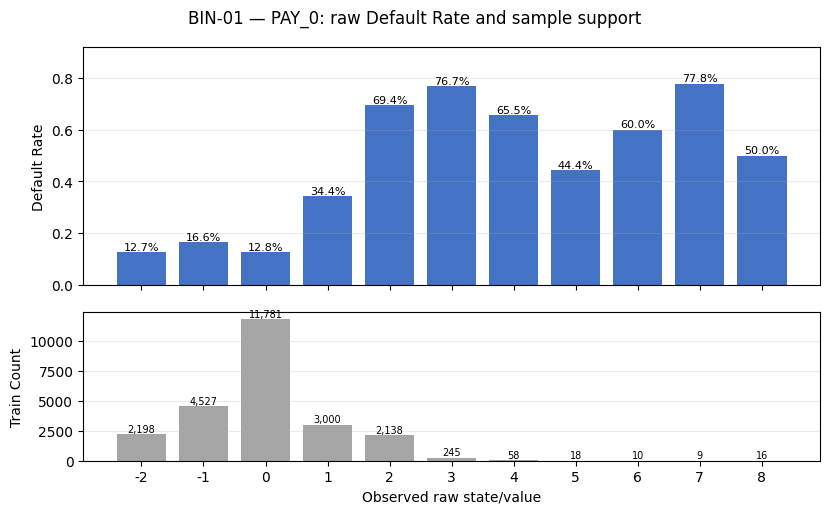

In [5]:
pay_0_table = build_raw_diagnostic("PAY_0")
register_diagnostic("PAY_0", pay_0_table)
display(pay_0_table)
print("Raw-state total IV:", f"{raw_iv_totals['PAY_0']:.12f}", "— diagnostic only; no selection decision")
print("Observed:", diagnostic_notes["PAY_0"])
render_default_support_figure("PAY_0", pay_0_table, "BIN-01")

## 5. PAY_2 raw-state diagnostics — BIN-02

**Question:** How do Train default risk and sample support vary across every observed raw PAY_2 code?

**Why it matters:** Raw-code risk must be interpreted together with support so rare high-severity states are not mistaken for stable estimates.

**Human decision needed:** Later decide whether any ordinal-adjacent states merit grouping. This Phase preserves every observed code and makes no final decision.

,State / Category,Count,Percent of Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,-2,3030,0.126250,2486,544,0.179538,0.133005,0.102468,0.260842,0.007966,None
1,-1,4845,0.201875,4071,774,0.159752,0.217805,0.145790,0.401433,0.028909,None
2,0,12573,0.523875,10567,2006,0.159548,0.565352,0.377849,0.402955,0.075555,None
3,1,25,0.001042,20,5,0.200000,0.001070,0.000942,0.127656,0.000016,None
4,2,3145,0.131042,1396,1749,0.556121,0.074688,0.329441,-1.484072,0.378071,None
5,3,254,0.010583,92,162,0.637795,0.004922,0.030514,-1.824446,0.046691,None
6,4,78,0.003250,39,39,0.500000,0.002087,0.007346,-1.258639,0.006620,None
7,5,21,0.000875,8,13,0.619048,0.000428,0.002449,-1.744146,0.003524,None
8,6,11,0.000458,3,8,0.727273,0.000161,0.001507,-2.239468,0.003015,None
9,7,17,0.000708,8,9,0.529412,0.000428,0.001695,-1.376422,0.001744,None


Raw-state total IV: inf — diagnostic only; no selection decision
Observed: Observed 11 raw states/categories; Default Rate spans 0.00% to 72.73%; smallest support is 8 with 1 rows (0.004%).


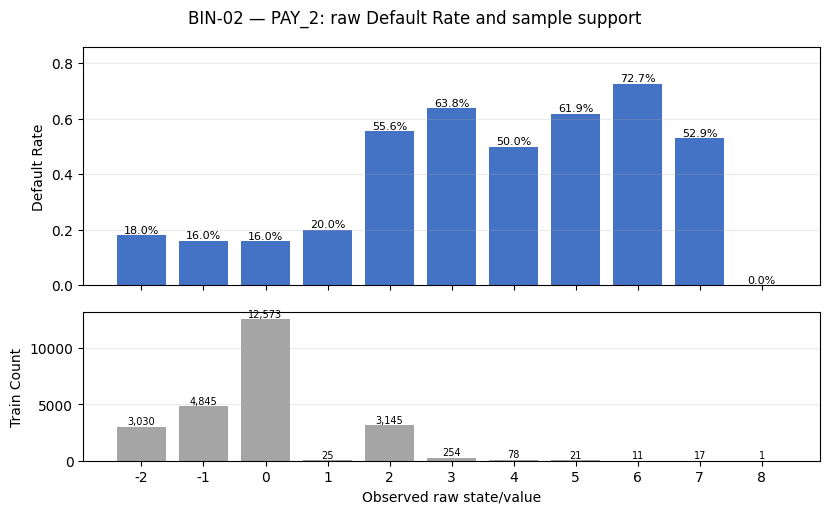

In [6]:
pay_2_table = build_raw_diagnostic("PAY_2")
register_diagnostic("PAY_2", pay_2_table)
display(pay_2_table)
print("Raw-state total IV:", f"{raw_iv_totals['PAY_2']:.12f}", "— diagnostic only; no selection decision")
print("Observed:", diagnostic_notes["PAY_2"])
render_default_support_figure("PAY_2", pay_2_table, "BIN-02")

## 6. PAY_3 raw-state diagnostics — BIN-03

**Question:** How do Train default risk and sample support vary across every observed raw PAY_3 code?

**Why it matters:** Raw-code risk must be interpreted together with support so rare high-severity states are not mistaken for stable estimates.

**Human decision needed:** Later decide whether any ordinal-adjacent states merit grouping. This Phase preserves every observed code and makes no final decision.

,State / Category,Count,Percent of Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,-2,3270,0.136250,2681,589,0.180122,0.143438,0.110944,0.256880,0.008347,None
1,-1,4733,0.197208,3997,736,0.155504,0.213846,0.138633,0.433431,0.032600,None
2,0,12636,0.526500,10416,2220,0.175689,0.557274,0.418158,0.287197,0.039954,None
3,1,3,0.000125,2,1,0.333333,0.000107,0.000188,-0.565491,0.000046,None
4,2,3049,0.127042,1469,1580,0.518203,0.078594,0.297608,-1.331482,0.291613,None
5,3,192,0.008000,81,111,0.578125,0.004334,0.020908,-1.573720,0.026083,None
6,4,60,0.002500,27,33,0.550000,0.001445,0.006216,-1.459309,0.006963,None
7,5,16,0.000667,6,10,0.625000,0.000321,0.001884,-1.769464,0.002765,None
8,6,19,0.000792,8,11,0.578947,0.000428,0.002072,-1.577092,0.002593,None
9,7,20,0.000833,4,16,0.800000,0.000214,0.003014,-2.644933,0.007405,None


Raw-state total IV: inf — diagnostic only; no selection decision
Observed: Observed 11 raw states/categories; Default Rate spans 15.55% to 100.00%; smallest support is 8 with 2 rows (0.008%).


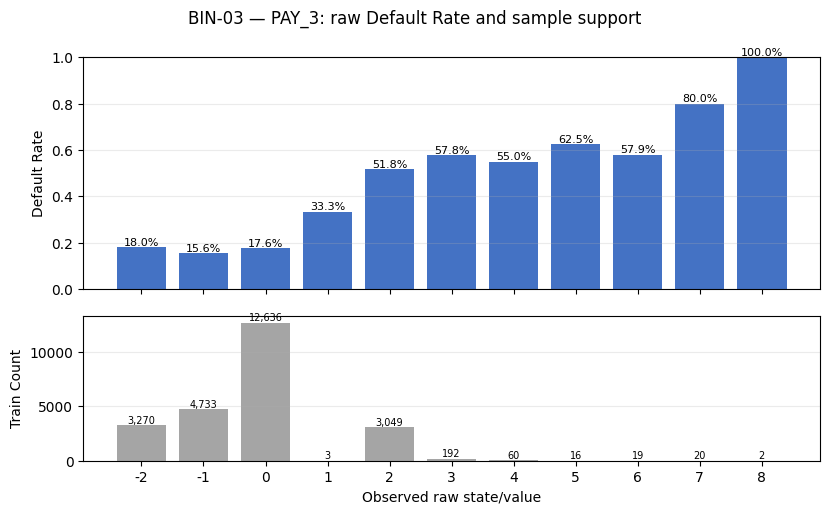

In [7]:
pay_3_table = build_raw_diagnostic("PAY_3")
register_diagnostic("PAY_3", pay_3_table)
display(pay_3_table)
print("Raw-state total IV:", f"{raw_iv_totals['PAY_3']:.12f}", "— diagnostic only; no selection decision")
print("Observed:", diagnostic_notes["PAY_3"])
render_default_support_figure("PAY_3", pay_3_table, "BIN-03")

## 7. PAY_4 raw-state diagnostics — BIN-04

**Question:** How do Train default risk and sample support vary across every observed raw PAY_4 code?

**Why it matters:** Raw-code risk must be interpreted together with support so rare high-severity states are not mistaken for stable estimates.

**Human decision needed:** Later decide whether any ordinal-adjacent states merit grouping. This Phase preserves every observed code and makes no final decision.

,State / Category,Count,Percent of Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,-2,3477,0.144875,2831,646,0.185792,0.151463,0.121680,0.218947,0.006521,None
1,-1,4531,0.188792,3809,722,0.159347,0.203788,0.135995,0.404458,0.027419,None
2,0,13180,0.549167,10747,2433,0.184598,0.574983,0.458278,0.226863,0.026476,None
3,1,2,0.000083,1,1,0.500000,0.000054,0.000188,-1.258639,0.000170,None
4,2,2542,0.105917,1204,1338,0.526357,0.064416,0.252025,-1.364165,0.255929,None
5,3,143,0.005958,56,87,0.608392,0.002996,0.016387,-1.699195,0.022754,None
6,4,53,0.002208,19,34,0.641509,0.001017,0.006404,-1.840560,0.009916,None
7,5,28,0.001167,16,12,0.428571,0.000856,0.002260,-0.970957,0.001364,None
8,6,3,0.000125,2,1,0.333333,0.000107,0.000188,-0.565491,0.000046,None
9,7,40,0.001667,6,34,0.850000,0.000321,0.006404,-2.993240,0.018209,None


Raw-state total IV: inf — diagnostic only; no selection decision
Observed: Observed 11 raw states/categories; Default Rate spans 15.93% to 100.00%; smallest support is 8 with 1 rows (0.004%).


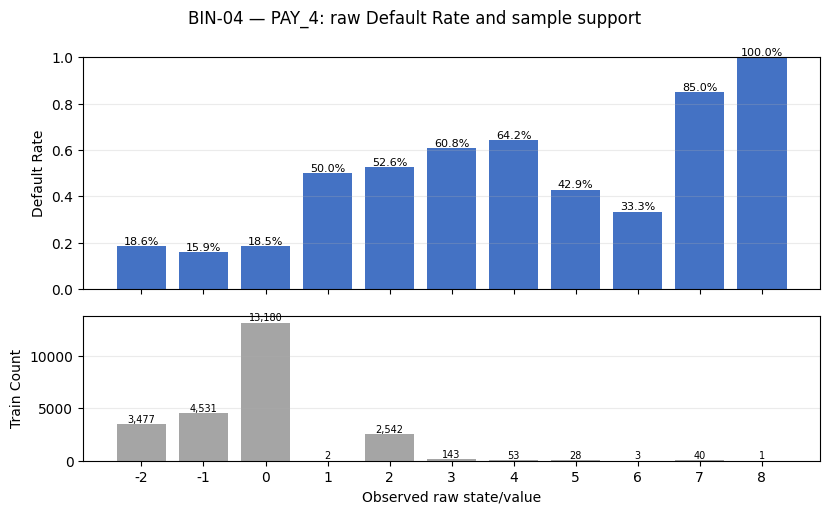

In [8]:
pay_4_table = build_raw_diagnostic("PAY_4")
register_diagnostic("PAY_4", pay_4_table)
display(pay_4_table)
print("Raw-state total IV:", f"{raw_iv_totals['PAY_4']:.12f}", "— diagnostic only; no selection decision")
print("Observed:", diagnostic_notes["PAY_4"])
render_default_support_figure("PAY_4", pay_4_table, "BIN-04")

## 8. PAY_5 raw-state diagnostics — BIN-05

**Question:** How do Train default risk and sample support vary across every observed raw PAY_5 code?

**Why it matters:** Raw-code risk must be interpreted together with support so rare high-severity states are not mistaken for stable estimates.

**Human decision needed:** Later decide whether any ordinal-adjacent states merit grouping. This Phase preserves every observed code and makes no final decision.

,State / Category,Count,Percent of Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,-2,3659,0.152458,2958,701,0.191582,0.158258,0.132040,0.181122,0.004749,None
1,-1,4417,0.184042,3681,736,0.166629,0.196940,0.138633,0.351071,0.020470,None
2,0,13560,0.565000,11000,2560,0.188791,0.588519,0.482200,0.199249,0.021184,None
3,2,2102,0.087583,954,1148,0.546147,0.051041,0.216237,-1.443752,0.238502,None
4,3,142,0.005917,58,84,0.591549,0.003103,0.015822,-1.629012,0.020720,None
5,4,65,0.002708,28,37,0.569231,0.001498,0.006969,-1.537352,0.008411,None
6,5,13,0.000542,6,7,0.538462,0.000321,0.001319,-1.412789,0.001409,None
7,6,3,0.000125,0,3,1.000000,0.000000,0.000565,-inf,inf,Good = 0 — Human Checkpoint required
8,7,38,0.001583,6,32,0.842105,0.000321,0.006028,-2.932615,0.016735,None
9,8,1,0.000042,0,1,1.000000,0.000000,0.000188,-inf,inf,Good = 0 — Human Checkpoint required


Raw-state total IV: inf — diagnostic only; no selection decision
Observed: Observed 10 raw states/categories; Default Rate spans 16.66% to 100.00%; smallest support is 8 with 1 rows (0.004%).


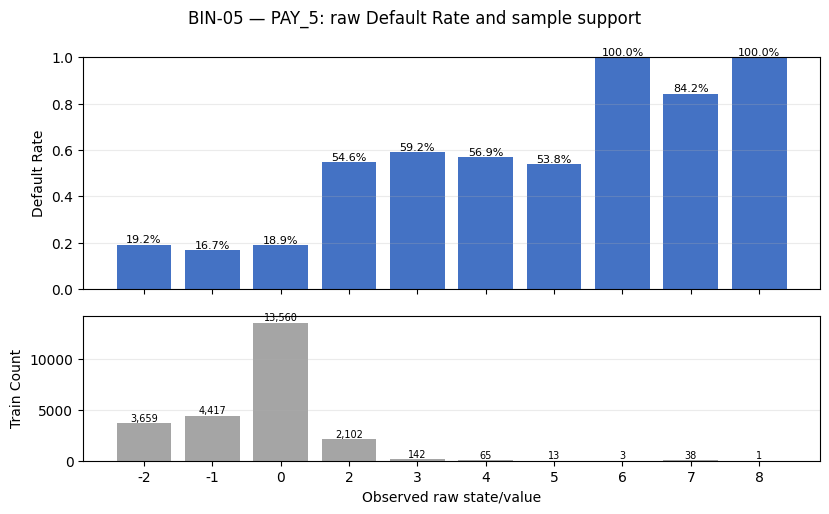

In [9]:
pay_5_table = build_raw_diagnostic("PAY_5")
register_diagnostic("PAY_5", pay_5_table)
display(pay_5_table)
print("Raw-state total IV:", f"{raw_iv_totals['PAY_5']:.12f}", "— diagnostic only; no selection decision")
print("Observed:", diagnostic_notes["PAY_5"])
render_default_support_figure("PAY_5", pay_5_table, "BIN-05")

## 9. PAY_6 raw-state diagnostics — BIN-06

**Question:** How do Train default risk and sample support vary across every observed raw PAY_6 code?

**Why it matters:** Raw-code risk must be interpreted together with support so rare high-severity states are not mistaken for stable estimates.

**Human decision needed:** Later decide whether any ordinal-adjacent states merit grouping. This Phase preserves every observed code and makes no final decision.

,State / Category,Count,Percent of Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,-2,3942,0.164250,3164,778,0.197362,0.169279,0.146544,0.144227,0.003279,None
1,-1,4576,0.190667,3803,773,0.168925,0.203467,0.145602,0.334628,0.019363,None
2,0,13008,0.542000,10543,2465,0.189499,0.564068,0.464306,0.194632,0.019417,None
3,2,2230,0.092917,1100,1130,0.506726,0.058852,0.212846,-1.285546,0.197967,None
4,3,149,0.006208,56,93,0.624161,0.002996,0.017517,-1.765886,0.025643,None
5,4,42,0.001750,13,29,0.690476,0.000696,0.005462,-2.060985,0.009825,None
6,5,8,0.000333,3,5,0.625000,0.000161,0.000942,-1.769464,0.001382,None
7,6,11,0.000458,3,8,0.727273,0.000161,0.001507,-2.239468,0.003015,None
8,7,33,0.001375,6,27,0.818182,0.000321,0.005086,-2.762716,0.013163,None
9,8,1,0.000042,0,1,1.000000,0.000000,0.000188,-inf,inf,Good = 0 — Human Checkpoint required


Raw-state total IV: inf — diagnostic only; no selection decision
Observed: Observed 10 raw states/categories; Default Rate spans 16.89% to 100.00%; smallest support is 8 with 1 rows (0.004%).


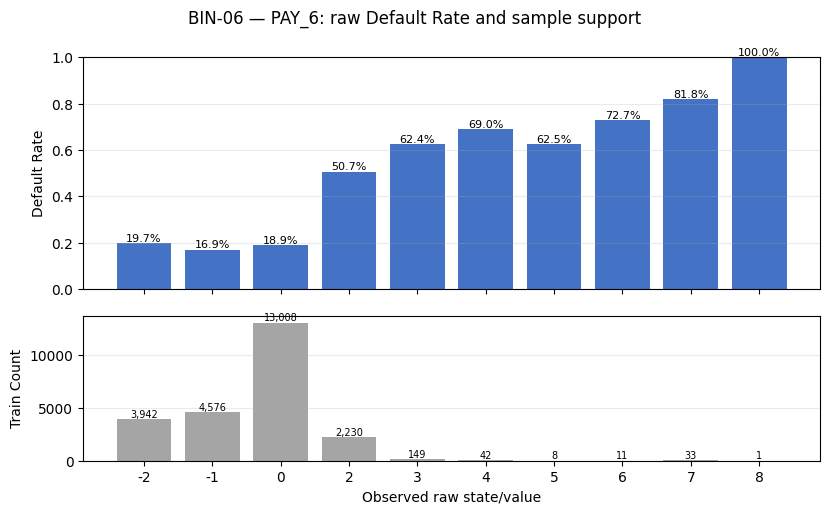

In [10]:
pay_6_table = build_raw_diagnostic("PAY_6")
register_diagnostic("PAY_6", pay_6_table)
display(pay_6_table)
print("Raw-state total IV:", f"{raw_iv_totals['PAY_6']:.12f}", "— diagnostic only; no selection decision")
print("Observed:", diagnostic_notes["PAY_6"])
render_default_support_figure("PAY_6", pay_6_table, "BIN-06")

## 10. delinquent_months raw-value diagnostics — BIN-07

**Question:** What risk progression and support appear across every observed integer value of delinquent_months?

**Why it matters:** Future grouping may only combine adjacent values and must distinguish stable progression from sparse-tail fluctuation.

**Human decision needed:** Review adjacent similarity and tail support later. This Phase does not merge any value.

,State / Category,Count,Percent of Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,0,15896,0.662333,14066,1830,0.115123,0.752555,0.344698,0.780806,0.318457,None
1,1,3572,0.148833,2502,1070,0.299552,0.133861,0.201545,-0.409207,0.027696,None
2,2,1532,0.063833,920,612,0.399478,0.049222,0.115276,-0.850997,0.056212,None
3,3,936,0.039000,465,471,0.503205,0.024878,0.088717,-1.271459,0.081169,None
4,4,767,0.031958,322,445,0.580183,0.017228,0.083820,-1.582161,0.105360,None
5,5,237,0.009875,95,142,0.599156,0.005083,0.026747,-1.660589,0.035976,None
6,6,1060,0.044167,321,739,0.697170,0.017174,0.139198,-2.092495,0.255334,None


Raw-value total IV: 0.880203687638 — diagnostic only; no selection decision
Observed: Observed 7 raw states/categories; Default Rate spans 11.51% to 69.72%; smallest support is 5 with 237 rows (0.988%).


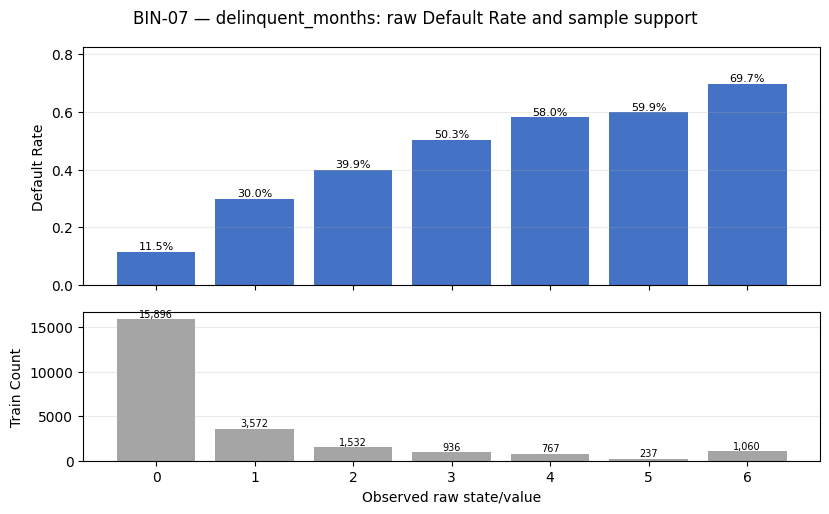

In [11]:
delinquent_months_table = build_raw_diagnostic("delinquent_months")
register_diagnostic("delinquent_months", delinquent_months_table)
display(delinquent_months_table)
print("Raw-value total IV:", f"{raw_iv_totals['delinquent_months']:.12f}", "— diagnostic only; no selection decision")
print("Observed:", diagnostic_notes["delinquent_months"])
render_default_support_figure("delinquent_months", delinquent_months_table, "BIN-07")

## 11. max_delinquency raw-value diagnostics — BIN-08

**Question:** What risk progression and support appear across every observed integer value of max_delinquency?

**Why it matters:** Future grouping may only combine adjacent values and must distinguish stable progression from sparse-tail fluctuation.

**Human decision needed:** Review adjacent similarity and tail support later. This Phase does not merge any value.

,State / Category,Count,Percent of Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,0,15896,0.662333,14066,1830,0.115123,0.752555,0.344698,0.780806,0.318457,None
1,1,1380,0.057500,1034,346,0.250725,0.055321,0.065172,-0.163887,0.001615,None
2,2,5785,0.241042,3240,2545,0.439931,0.173345,0.479375,-1.017196,0.311292,None
3,3,629,0.026208,234,395,0.627981,0.012519,0.074402,-1.782203,0.110287,None
4,4,173,0.007208,66,107,0.618497,0.003531,0.020154,-1.741813,0.028955,None
5,5,49,0.002042,25,24,0.489796,0.001338,0.004521,-1.217817,0.003876,None
6,6,20,0.000833,9,11,0.550000,0.000482,0.002072,-1.459309,0.002321,None
7,7,49,0.002042,8,41,0.836735,0.000428,0.007723,-2.892769,0.021102,None
8,8,19,0.000792,9,10,0.526316,0.000482,0.001884,-1.363999,0.001912,None


Raw-value total IV: 0.799817181916 — diagnostic only; no selection decision
Observed: Observed 9 raw states/categories; Default Rate spans 11.51% to 83.67%; smallest support is 8 with 19 rows (0.079%).


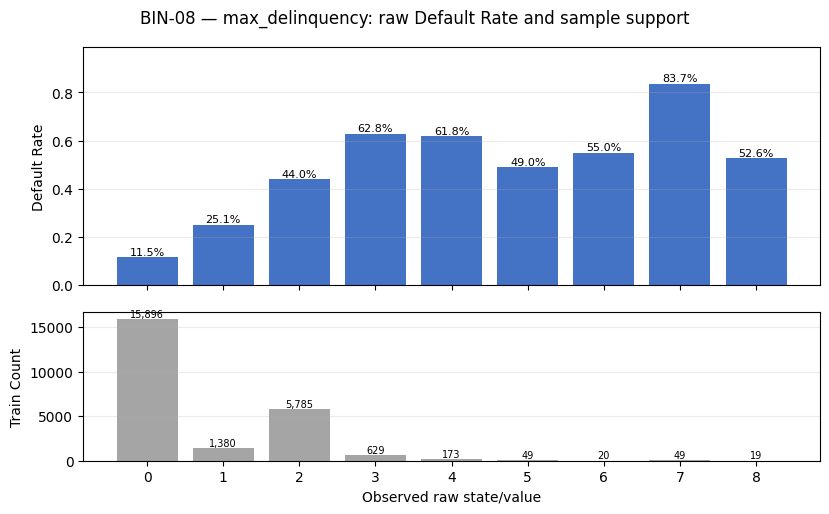

In [12]:
max_delinquency_table = build_raw_diagnostic("max_delinquency")
register_diagnostic("max_delinquency", max_delinquency_table)
display(max_delinquency_table)
print("Raw-value total IV:", f"{raw_iv_totals['max_delinquency']:.12f}", "— diagnostic only; no selection decision")
print("Observed:", diagnostic_notes["max_delinquency"])
render_default_support_figure("max_delinquency", max_delinquency_table, "BIN-08")

## 12. severe_delinquent_months raw-value diagnostics — BIN-09

**Question:** What risk progression and support appear across every observed integer value of severe_delinquent_months?

**Why it matters:** Future grouping may only combine adjacent values and must distinguish stable progression from sparse-tail fluctuation.

**Human decision needed:** Review adjacent similarity and tail support later. This Phase does not merge any value.

,State / Category,Count,Percent of Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,0,17276,0.719833,15100,2176,0.125955,0.807875,0.409870,0.678568,0.270074,None
1,1,2799,0.116625,1887,912,0.325831,0.100958,0.171784,-0.531535,0.037647,None
2,2,1279,0.053292,708,571,0.446443,0.037879,0.107553,-1.043584,0.072711,None
3,3,861,0.035875,400,461,0.535424,0.021401,0.086834,-1.400572,0.091644,None
4,4,570,0.023750,224,346,0.607018,0.011984,0.065172,-1.693431,0.090070,None
5,5,483,0.020125,197,286,0.592133,0.010540,0.053871,-1.631427,0.070691,None
6,6,732,0.030500,175,557,0.760929,0.009363,0.104916,-2.416418,0.230897,None


Raw-value total IV: 0.863732879371 — diagnostic only; no selection decision
Observed: Observed 7 raw states/categories; Default Rate spans 12.60% to 76.09%; smallest support is 5 with 483 rows (2.013%).


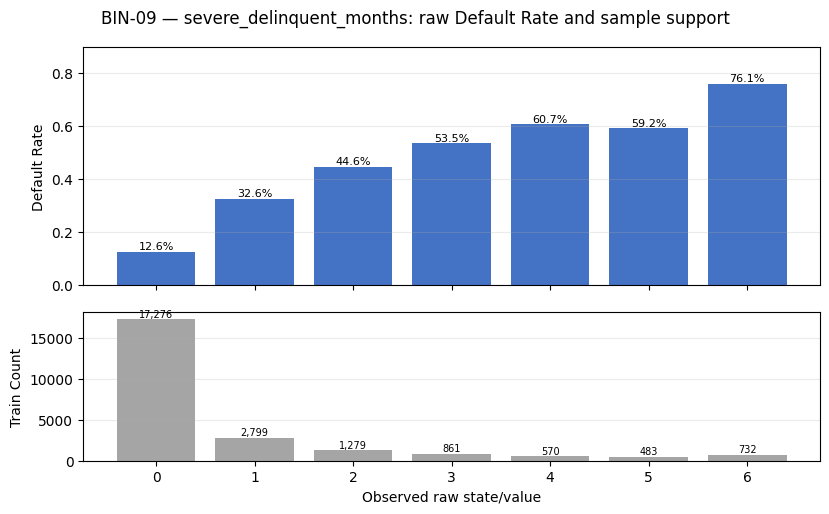

In [13]:
severe_delinquent_months_table = build_raw_diagnostic("severe_delinquent_months")
register_diagnostic("severe_delinquent_months", severe_delinquent_months_table)
display(severe_delinquent_months_table)
print("Raw-value total IV:", f"{raw_iv_totals['severe_delinquent_months']:.12f}", "— diagnostic only; no selection decision")
print("Observed:", diagnostic_notes["severe_delinquent_months"])
render_default_support_figure("severe_delinquent_months", severe_delinquent_months_table, "BIN-09")

## 13. SEX raw-category diagnostics

SEX retains both observed raw categories. No merge is proposed: merging both would remove all discrimination. Whether the variable is retained later belongs to Stage 4.4, not this Phase.

In [14]:
sex_order = sorted(train_work["SEX"].unique().tolist())
sex_table = build_raw_diagnostic("SEX", display_order=sex_order)
register_diagnostic("SEX", sex_table)
display(sex_table)
print("Raw-category total IV:", f"{raw_iv_totals['SEX']:.12f}", "— diagnostic only; no selection decision")
print("Observed:", diagnostic_notes["SEX"])
print("Merge boundary: no SEX-category merge is proposed in Stage 4.2A.")

,State / Category,Count,Percent of Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,1,9486,0.395250,7174,2312,0.243728,0.383821,0.435487,-0.126288,0.006525,None
1,2,14514,0.604750,11517,2997,0.206490,0.616179,0.564513,0.087574,0.004525,None


Raw-category total IV: 0.011049354693 — diagnostic only; no selection decision
Observed: Observed 2 raw states/categories; Default Rate spans 20.65% to 24.37%; smallest support is 1 with 9,486 rows (39.525%).
Merge boundary: no SEX-category merge is proposed in Stage 4.2A.


## 14. EDUCATION_GROUP raw-category diagnostics

The frozen four categories remain separate. Similar WOE alone is not sufficient to merge semantically distinct categories. Other / Unknown is explicitly checked for sparse support and remains a Human Checkpoint item, not an automatic merge.

In [15]:
education_group_table = build_raw_diagnostic("EDUCATION_GROUP", display_order=EDUCATION_ORDER)
register_diagnostic("EDUCATION_GROUP", education_group_table)
education_other_row = education_group_table.loc[
    education_group_table["State / Category"] == "Other / Unknown"
].iloc[0]
education_sparse = bool(education_other_row["Percent of Train"] < 0.03)
assert education_sparse
display(education_group_table)
print("Raw-category total IV:", f"{raw_iv_totals['EDUCATION_GROUP']:.12f}", "— diagnostic only; no selection decision")
print("Observed:", diagnostic_notes["EDUCATION_GROUP"])
print(
    "Sparse special-category flag — Other / Unknown:",
    f"{int(education_other_row['Count']):,} rows ({education_other_row['Percent of Train']:.3%});",
    "flagged for Human Checkpoint; not merged.",
)

,State / Category,Count,Percent of Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,Graduate School,8455,0.352292,6824,1631,0.192904,0.365096,0.307214,0.172614,0.009991,None
1,University,11256,0.469000,8582,2674,0.237562,0.459151,0.503673,-0.092547,0.004120,None
2,High School,3903,0.162625,2927,976,0.250064,0.156599,0.183839,-0.160368,0.004368,None
3,Other / Unknown,386,0.016083,358,28,0.072539,0.019154,0.005274,1.289690,0.017900,None


Raw-category total IV: 0.036380079009 — diagnostic only; no selection decision
Observed: Observed 4 raw states/categories; Default Rate spans 7.25% to 25.01%; smallest support is Other / Unknown with 386 rows (1.608%).
Sparse special-category flag — Other / Unknown: 386 rows (1.608%); flagged for Human Checkpoint; not merged.


## 15. MARRIAGE_GROUP raw-category diagnostics

The frozen three categories remain separate. Other / Unknown is explicitly checked for sparse support and is not automatically merged into Married or Single.

In [16]:
marriage_group_table = build_raw_diagnostic("MARRIAGE_GROUP", display_order=MARRIAGE_ORDER)
register_diagnostic("MARRIAGE_GROUP", marriage_group_table)
marriage_other_row = marriage_group_table.loc[
    marriage_group_table["State / Category"] == "Other / Unknown"
].iloc[0]
marriage_sparse = bool(marriage_other_row["Percent of Train"] < 0.03)
assert marriage_sparse
display(marriage_group_table)
print("Raw-category total IV:", f"{raw_iv_totals['MARRIAGE_GROUP']:.12f}", "— diagnostic only; no selection decision")
print("Observed:", diagnostic_notes["MARRIAGE_GROUP"])
print(
    "Sparse special-category flag — Other / Unknown:",
    f"{int(marriage_other_row['Count']):,} rows ({marriage_other_row['Percent of Train']:.3%});",
    "flagged for Human Checkpoint; not merged.",
)

,State / Category,Count,Percent of Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,Married,10892,0.453833,8354,2538,0.233015,0.446953,0.478056,-0.067275,0.002092,None
1,Single,12806,0.533583,10112,2694,0.210370,0.541009,0.507440,0.064057,0.002150,None
2,Other / Unknown,302,0.012583,225,77,0.254967,0.012038,0.014504,-0.186344,0.000459,None


Raw-category total IV: 0.004702252234 — diagnostic only; no selection decision
Observed: Observed 3 raw states/categories; Default Rate spans 21.04% to 25.50%; smallest support is Other / Unknown with 302 rows (1.258%).
Sparse special-category flag — Other / Unknown: 302 rows (1.258%); flagged for Human Checkpoint; not merged.


## 16. Required PAY=1, boundary, and high-severity evidence

The supporting tables keep the fixed month order. They do not create pseudo-states or aggregate codes:

- PAY=1 is reported month by month.
- Codes 0, 1, 2, and each observed code 3–8 remain individual rows.
- High-severity support is exposed separately to assess tail sparsity, but no tail bin is created.

In [17]:
pay_one_rows = []
pay_boundary_rows = []
high_tail_rows = []
for variable in PAY_VARIABLES:
    table = diagnostic_tables[variable]
    state_numeric = pd.to_numeric(table["State / Category"])
    code_one = table.loc[state_numeric == 1]
    if code_one.empty:
        pay_one_rows.append({
            "PAY variable": variable, "Code 1 exists": False, "Count": "not observed",
            "Percent of Train": "not observed", "Default Rate": "not observed", "WOE": "not observed",
        })
    else:
        row = code_one.iloc[0]
        pay_one_rows.append({
            "PAY variable": variable, "Code 1 exists": True, "Count": int(row["Count"]),
            "Percent of Train": float(row["Percent of Train"]),
            "Default Rate": float(row["Default Rate"]), "WOE": float(row["WOE"]),
        })

    boundary = table.loc[state_numeric.isin(range(0, 9)), [
        "State / Category", "Count", "Percent of Train", "Default Rate", "WOE"
    ]].copy()
    boundary.insert(0, "PAY variable", variable)
    pay_boundary_rows.append(boundary)

    tail = table.loc[state_numeric.isin(range(3, 9)), [
        "State / Category", "Count", "Percent of Train", "Default Rate", "WOE"
    ]].copy()
    if not tail.empty:
        tail.insert(0, "PAY variable", variable)
        high_tail_rows.append(tail)

pay_one_evidence = pd.DataFrame(pay_one_rows)
pay_boundary_evidence = pd.concat(pay_boundary_rows, ignore_index=True)
high_tail_evidence = pd.concat(high_tail_rows, ignore_index=True)

assert pay_one_evidence["PAY variable"].tolist() == PAY_VARIABLES
assert pay_boundary_evidence.groupby("PAY variable", sort=False).ngroup().is_monotonic_increasing
assert high_tail_evidence["State / Category"].between(3, 8).all()

print("PAY=1 month-by-month evidence:")
display(pay_one_evidence)
print("PAY boundary evidence — codes remain individual raw states:")
display(pay_boundary_evidence)
print("Observed high-severity tail support — no aggregation:")
display(high_tail_evidence)

PAY=1 month-by-month evidence:


,PAY variable,Code 1 exists,Count,Percent of Train,Default Rate,WOE
0,PAY_0,True,3000,0.125000,0.343667,-0.611642
1,PAY_2,True,25,0.001042,0.200000,0.127656
2,PAY_3,True,3,0.000125,0.333333,-0.565491
3,PAY_4,True,2,0.000083,0.500000,-1.258639
4,PAY_5,False,not observed,not observed,not observed,not observed
5,PAY_6,False,not observed,not observed,not observed,not observed


PAY boundary evidence — codes remain individual raw states:


,PAY variable,State / Category,Count,Percent of Train,Default Rate,WOE
0,PAY_0,0,11781,0.490875,0.128003,0.660096
1,PAY_0,1,3000,0.125000,0.343667,-0.611642
2,PAY_0,2,2138,0.089083,0.693639,-2.075826
3,PAY_0,3,245,0.010208,0.767347,-2.452029
4,PAY_0,4,58,0.002417,0.655172,-1.900493
5,PAY_0,5,18,0.000750,0.444444,-1.035495
6,PAY_0,6,10,0.000417,0.600000,-1.664104
7,PAY_0,7,9,0.000375,0.777778,-2.511402
8,PAY_0,8,16,0.000667,0.500000,-1.258639
9,PAY_2,0,12573,0.523875,0.159548,0.402955


Observed high-severity tail support — no aggregation:


,PAY variable,State / Category,Count,Percent of Train,Default Rate,WOE
0,PAY_0,3,245,0.010208,0.767347,-2.452029
1,PAY_0,4,58,0.002417,0.655172,-1.900493
2,PAY_0,5,18,0.000750,0.444444,-1.035495
3,PAY_0,6,10,0.000417,0.600000,-1.664104
4,PAY_0,7,9,0.000375,0.777778,-2.511402
5,PAY_0,8,16,0.000667,0.500000,-1.258639
6,PAY_2,3,254,0.010583,0.637795,-1.824446
7,PAY_2,4,78,0.003250,0.500000,-1.258639
8,PAY_2,5,21,0.000875,0.619048,-1.744146
9,PAY_2,6,11,0.000458,0.727273,-2.239468


## 17. Zero-event review and fixed-order cross-variable summary

Raw total IV appears only because it is the sum of each formal raw table. The summary remains in the pre-authorized 12-variable order; it is not sorted, ranked, or used for retain/drop decisions.

Any Good=0 or Bad=0 row remains visible with raw infinite/undefined WOE/IV. No 0.5 smoothing is applied in Stage 4.2A.

In [18]:
zero_event_records = []
summary_rows = []
for variable in SCOPE_VARIABLES:
    table = diagnostic_tables[variable]
    zero_rows = table.loc[table["Zero-event flag"] != "None"].copy()
    if not zero_rows.empty:
        zero_rows.insert(0, "Variable", variable)
        zero_event_records.append(zero_rows)

    smallest = table.loc[table["Count"].idxmin()]
    note = "ordinal raw states preserved" if variable in PAY_VARIABLES + DELINQUENCY_VARIABLES else "semantic categories preserved"
    if variable in ["EDUCATION_GROUP", "MARRIAGE_GROUP"]:
        note += "; Other / Unknown flagged sparse"
    summary_rows.append({
        "Variable": variable,
        "Raw states/categories": len(table),
        "Total raw-state IV": raw_iv_totals[variable],
        "Zero-event issue": bool((table["Zero-event flag"] != "None").any()),
        "Smallest raw-state support": int(smallest["Count"]),
        "Diagnostic notes": note,
        "Decision boundary": "diagnostic only — no variable-selection decision",
    })

cross_variable_summary = pd.DataFrame(summary_rows)
assert cross_variable_summary["Variable"].tolist() == SCOPE_VARIABLES
assert not cross_variable_summary.columns.isin(["Rank", "Retain", "Drop"]).any()

if zero_event_records:
    zero_event_evidence = pd.concat(zero_event_records, ignore_index=True)
    print("Zero-Good/zero-Bad raw states — no smoothing; Human Checkpoint required:")
    display(zero_event_evidence)
else:
    zero_event_evidence = pd.DataFrame()
    print("Zero-event review: no observed raw state/category has Good=0 or Bad=0; no smoothing applied.")

print("Fixed-scope-order summary — diagnostic only; no ranking or selection:")
display(cross_variable_summary)

Zero-Good/zero-Bad raw states — no smoothing; Human Checkpoint required:


,Variable,State / Category,Count,Percent of Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution,Zero-event flag
0,PAY_2,8,1,0.000042,1,0,0.000000,0.000054,0.000000,inf,inf,Bad = 0 — Human Checkpoint required
1,PAY_3,8,2,0.000083,0,2,1.000000,0.000000,0.000377,-inf,inf,Good = 0 — Human Checkpoint required
2,PAY_4,8,1,0.000042,0,1,1.000000,0.000000,0.000188,-inf,inf,Good = 0 — Human Checkpoint required
3,PAY_5,6,3,0.000125,0,3,1.000000,0.000000,0.000565,-inf,inf,Good = 0 — Human Checkpoint required
4,PAY_5,8,1,0.000042,0,1,1.000000,0.000000,0.000188,-inf,inf,Good = 0 — Human Checkpoint required
5,PAY_6,8,1,0.000042,0,1,1.000000,0.000000,0.000188,-inf,inf,Good = 0 — Human Checkpoint required


Fixed-scope-order summary — diagnostic only; no ranking or selection:


,Variable,Raw states/categories,Total raw-state IV,Zero-event issue,Smallest raw-state support,Diagnostic notes,Decision boundary
0,PAY_0,11,0.889401,False,9,ordinal raw states preserved,diagnostic only — no variable-selection decision
1,PAY_2,11,inf,True,1,ordinal raw states preserved,diagnostic only — no variable-selection decision
2,PAY_3,11,inf,True,2,ordinal raw states preserved,diagnostic only — no variable-selection decision
3,PAY_4,11,inf,True,1,ordinal raw states preserved,diagnostic only — no variable-selection decision
4,PAY_5,10,inf,True,1,ordinal raw states preserved,diagnostic only — no variable-selection decision
5,PAY_6,10,inf,True,1,ordinal raw states preserved,diagnostic only — no variable-selection decision
6,delinquent_months,7,0.880204,False,237,ordinal raw states preserved,diagnostic only — no variable-selection decision
7,max_delinquency,9,0.799817,False,19,ordinal raw states preserved,diagnostic only — no variable-selection decision
8,severe_delinquent_months,7,0.863733,False,483,ordinal raw states preserved,diagnostic only — no variable-selection decision
9,SEX,2,0.011049,False,9486,semantic categories preserved,diagnostic only — no variable-selection decision


## 18. Non-binding candidate observations

Every statement below is evidence for later review, not a final bin definition. Observations preserve month-specific behavior, ordinal adjacency, and raw support. They do not specify a final number of bins, approve a grouping, or recommend variable retain/drop.

In [19]:
candidate_rows = []
for variable in PAY_VARIABLES:
    table = diagnostic_tables[variable].copy()
    table["_state"] = pd.to_numeric(table["State / Category"])
    lower = table.loc[table["_state"].isin([-2, -1, 0])].sort_values("_state")
    code_one = table.loc[table["_state"] == 1]
    code_two = table.loc[table["_state"] == 2]
    tail = table.loc[table["_state"].between(3, 8)].sort_values("_state")

    lower_text = (
        f"adjacent -2/-1/0 Default Rates span {lower['Default Rate'].min():.2%}–{lower['Default Rate'].max():.2%} "
        f"with supports {', '.join(str(int(x)) for x in lower['Count'])}; may be reviewed without presuming a merge"
    )
    one_text = (
        "code 1 not observed"
        if code_one.empty else
        f"code 1: {int(code_one.iloc[0]['Count']):,} rows, "
        f"{code_one.iloc[0]['Default Rate']:.2%} Default Rate, WOE {code_one.iloc[0]['WOE']:.4f}"
    )
    two_text = (
        "code 2 not observed"
        if code_two.empty else
        f"code 2: {int(code_two.iloc[0]['Count']):,} rows, "
        f"{code_two.iloc[0]['Default Rate']:.2%} Default Rate, WOE {code_two.iloc[0]['WOE']:.4f}; "
        "its boundary relative to code 0/1 may be reviewed"
    )
    tail_text = (
        "no codes 3–8 observed"
        if tail.empty else
        "observed codes 3–8 supports: " + ", ".join(
            f"{int(row['_state'])}={int(row['Count'])}" for _, row in tail.iterrows()
        ) + "; contiguous tail consolidation may be reviewed only after considering risk and sparse support"
    )
    candidate_rows.append({
        "Variable": variable,
        "Lower adjacent-state evidence": lower_text,
        "PAY=1 evidence": one_text,
        "PAY=2 boundary evidence": two_text,
        "High-tail evidence": tail_text,
        "Status": "candidate for later Human review — no final grouping",
    })

for variable in DELINQUENCY_VARIABLES:
    table = diagnostic_tables[variable].copy()
    table["_state"] = pd.to_numeric(table["State / Category"])
    table = table.sort_values("_state")
    adjacent = []
    for left_index in range(len(table) - 1):
        left = table.iloc[left_index]
        right = table.iloc[left_index + 1]
        assert int(right["_state"]) - int(left["_state"]) == 1
        adjacent.append((
            abs(float(right["Default Rate"]) - float(left["Default Rate"])),
            int(left["_state"]), int(right["_state"]),
            int(left["Count"]), int(right["Count"]),
        ))
    gap, left_state, right_state, left_count, right_count = min(adjacent)
    candidate_rows.append({
        "Variable": variable,
        "Lower adjacent-state evidence": (
            f"smallest adjacent Default Rate gap is {gap:.2%} for {left_state} and {right_state} "
            f"(supports {left_count:,} and {right_count:,}); may be reviewed, not merged here"
        ),
        "PAY=1 evidence": "not applicable",
        "PAY=2 boundary evidence": "not applicable",
        "High-tail evidence": "raw high values remain separately visible",
        "Status": "candidate for later Human review — no final grouping",
    })

candidate_observations = pd.DataFrame(candidate_rows)
assert candidate_observations["Variable"].tolist() == PAY_VARIABLES + DELINQUENCY_VARIABLES
assert candidate_observations["Status"].str.contains("no final grouping").all()
display(candidate_observations)

print(
    "Categorical checkpoint facts:",
    f"EDUCATION_GROUP Other / Unknown = {int(education_other_row['Count']):,} "
    f"({education_other_row['Percent of Train']:.3%});",
    f"MARRIAGE_GROUP Other / Unknown = {int(marriage_other_row['Count']):,} "
    f"({marriage_other_row['Percent of Train']:.3%}).",
)
print("Both are sparse special categories for review; neither is merged or assigned a final treatment.")

,Variable,Lower adjacent-state evidence,PAY=1 evidence,PAY=2 boundary evidence,High-tail evidence,Status
0,PAY_0,adjacent -2/-1/0 Default Rates span 12.69%–16....,"code 1: 3,000 rows, 34.37% Default Rate, WOE -...","code 2: 2,138 rows, 69.36% Default Rate, WOE -...","observed codes 3–8 supports: 3=245, 4=58, 5=18...",candidate for later Human review — no final gr...
1,PAY_2,adjacent -2/-1/0 Default Rates span 15.95%–17....,"code 1: 25 rows, 20.00% Default Rate, WOE 0.1277","code 2: 3,145 rows, 55.61% Default Rate, WOE -...","observed codes 3–8 supports: 3=254, 4=78, 5=21...",candidate for later Human review — no final gr...
2,PAY_3,adjacent -2/-1/0 Default Rates span 15.55%–18....,"code 1: 3 rows, 33.33% Default Rate, WOE -0.5655","code 2: 3,049 rows, 51.82% Default Rate, WOE -...","observed codes 3–8 supports: 3=192, 4=60, 5=16...",candidate for later Human review — no final gr...
3,PAY_4,adjacent -2/-1/0 Default Rates span 15.93%–18....,"code 1: 2 rows, 50.00% Default Rate, WOE -1.2586","code 2: 2,542 rows, 52.64% Default Rate, WOE -...","observed codes 3–8 supports: 3=143, 4=53, 5=28...",candidate for later Human review — no final gr...
4,PAY_5,adjacent -2/-1/0 Default Rates span 16.66%–19....,code 1 not observed,"code 2: 2,102 rows, 54.61% Default Rate, WOE -...","observed codes 3–8 supports: 3=142, 4=65, 5=13...",candidate for later Human review — no final gr...
5,PAY_6,adjacent -2/-1/0 Default Rates span 16.89%–19....,code 1 not observed,"code 2: 2,230 rows, 50.67% Default Rate, WOE -...","observed codes 3–8 supports: 3=149, 4=42, 5=8,...",candidate for later Human review — no final gr...
6,delinquent_months,smallest adjacent Default Rate gap is 1.90% fo...,not applicable,not applicable,raw high values remain separately visible,candidate for later Human review — no final gr...
7,max_delinquency,smallest adjacent Default Rate gap is 0.95% fo...,not applicable,not applicable,raw high values remain separately visible,candidate for later Human review — no final gr...
8,severe_delinquent_months,smallest adjacent Default Rate gap is 1.49% fo...,not applicable,not applicable,raw high values remain separately visible,candidate for later Human review — no final gr...


Categorical checkpoint facts: EDUCATION_GROUP Other / Unknown = 386 (1.608%); MARRIAGE_GROUP Other / Unknown = 302 (1.258%).
Both are sparse special categories for review; neither is merged or assigned a final treatment.


## 19. Scope confirmation and mandatory Human Checkpoint

Stage 4.2A evidence is complete. The Architect/user must now review raw PAY states month by month, adjacent delinquency values, and sparse categorical categories.

**Stop here.** Do not create final groupings, start Stage 4.2B, analyze Stage 4.3 continuous predictors, select variables, fit a model, run KFold, use Holdout Test target information, stage, commit, or push.

In [20]:
assert TEST_SEAL_STATUS.startswith("SEALED")
assert list(diagnostic_tables) == SCOPE_VARIABLES
assert len(diagnostic_tables) == 12
assert figure_ids == [f"BIN-{number:02d}" for number in range(1, 10)]
assert len(figure_ids) == 9 and len(set(figure_ids)) == 9
assert set(diagnostic_tables) == set(SCOPE_VARIABLES)
assert all(int(table["Count"].sum()) == 24000 for table in diagnostic_tables.values())
assert all("State / Category" in table.columns for table in diagnostic_tables.values())
assert all(not table["State / Category"].duplicated().any() for table in diagnostic_tables.values())
assert len(pay_one_evidence) == 6
assert not high_tail_evidence.empty
assert education_sparse and marriage_sparse

FINAL_BINNING_PERFORMED = False
SMOOTHING_PERFORMED = False
VARIABLE_SELECTION_PERFORMED = False
CONTINUOUS_BINNING_PERFORMED = False
MODELING_PERFORMED = False
KFOLD_EXECUTED = False
TEST_TARGET_ANALYZED = False
assert not any([
    FINAL_BINNING_PERFORMED, SMOOTHING_PERFORMED, VARIABLE_SELECTION_PERFORMED,
    CONTINUOUS_BINNING_PERFORMED, MODELING_PERFORMED, KFOLD_EXECUTED,
    TEST_TARGET_ANALYZED,
])

final_status = pd.DataFrame({"Result": [
    "PASS — locked split and both ID hashes reproduced",
    "PASS — Holdout Test deleted after technical assertions",
    "PASS — exact frozen Train feature definitions reproduced",
    "PASS — exactly 12 raw diagnostic tables in fixed order",
    "PASS — nine unique diagnostic figures BIN-01 through BIN-09",
    "PASS — PAY=1, code 2 boundary, and high-tail evidence retained",
    "PASS — no raw state/value/category merged; no smoothing",
    "PASS — no final bins, selection, continuous binning, model, KFold, AUC, or KS",
    "PENDING — Architect/user Human Checkpoint for Stage 4.2B decisions",
]}, index=[
    "Split identity", "Test sealing", "Stage 3 feature reproduction",
    "Diagnostic tables", "Diagnostic figures", "Required PAY evidence",
    "Raw-state integrity", "Prohibited operations", "Next gate",
])
display(final_status)
print("Stage 4.2A complete — final grouping pending Architect/user Human Checkpoint.")

,Result
Split identity,PASS — locked split and both ID hashes reproduced
Test sealing,PASS — Holdout Test deleted after technical as...
Stage 3 feature reproduction,PASS — exact frozen Train feature definitions ...
Diagnostic tables,PASS — exactly 12 raw diagnostic tables in fix...
Diagnostic figures,PASS — nine unique diagnostic figures BIN-01 t...
Required PAY evidence,"PASS — PAY=1, code 2 boundary, and high-tail e..."
Raw-state integrity,PASS — no raw state/value/category merged; no ...
Prohibited operations,"PASS — no final bins, selection, continuous bi..."
Next gate,PENDING — Architect/user Human Checkpoint for ...


Stage 4.2A complete — final grouping pending Architect/user Human Checkpoint.


# Stage 4.2B — Human-Approved Final Binning Implementation

This section implements the frozen Human Checkpoint decisions without reopening bin design. It uses Train only after the already-completed technical split assertions and Holdout deletion. All 12 variables remain candidates; retention, redundancy, and stability decisions are deferred to Stage 4.4/4.6.


In [21]:
PHASE_B_STATUS = "IMPLEMENTING FROZEN HUMAN-APPROVED GROUPINGS"
APPROVED_PAY_DOMAIN = tuple(range(-2, 9))
APPROVED_PAY_DOMAIN_SET = set(APPROVED_PAY_DOMAIN)
PAY_0_BIN_ORDER = ["[-2,-1,0]", "[1]", "[2+]"]
PAY_LATER_BIN_ORDER = ["[-2,-1,0,1]", "[2]", "[3+]"]
DELINQUENT_MONTHS_BIN_ORDER = ["0", "1", "2", "3", "4+"]
MAX_DELINQUENCY_BIN_ORDER = ["0", "1", "2", "3+"]
SEVERE_DELINQUENT_MONTHS_BIN_ORDER = ["0", "1", "2", "3", "4+"]
PAY_0_MAPPING = {-2:"[-2,-1,0]",-1:"[-2,-1,0]",0:"[-2,-1,0]",1:"[1]",2:"[2+]",3:"[2+]",4:"[2+]",5:"[2+]",6:"[2+]",7:"[2+]",8:"[2+]"}
PAY_LATER_MAPPING = {-2:"[-2,-1,0,1]",-1:"[-2,-1,0,1]",0:"[-2,-1,0,1]",1:"[-2,-1,0,1]",2:"[2]",3:"[3+]",4:"[3+]",5:"[3+]",6:"[3+]",7:"[3+]",8:"[3+]"}
DELINQUENT_MONTHS_MAPPING = {0:"0",1:"1",2:"2",3:"3",4:"4+",5:"4+",6:"4+"}
MAX_DELINQUENCY_MAPPING = {0:"0",1:"1",2:"2",3:"3+",4:"3+",5:"3+",6:"3+",7:"3+",8:"3+"}
SEVERE_DELINQUENT_MONTHS_MAPPING = {0:"0",1:"1",2:"2",3:"3",4:"4+",5:"4+",6:"4+"}
assert set(PAY_0_MAPPING)==APPROVED_PAY_DOMAIN_SET
assert set(PAY_LATER_MAPPING)==APPROVED_PAY_DOMAIN_SET
print(PHASE_B_STATUS)
print("Approved PAY_0:", " / ".join(PAY_0_BIN_ORDER))
print("Approved PAY_2–PAY_6:", " / ".join(PAY_LATER_BIN_ORDER))
print("Rejected and not implemented: incomplete PAY_5/PAY_6 code-1 rule and both 4-5 / 6 alternatives.")


IMPLEMENTING FROZEN HUMAN-APPROVED GROUPINGS
Approved PAY_0: [-2,-1,0] / [1] / [2+]
Approved PAY_2–PAY_6: [-2,-1,0,1] / [2] / [3+]
Rejected and not implemented: incomplete PAY_5/PAY_6 code-1 rule and both 4-5 / 6 alternatives.


## 20. Frozen mapping definitions and synthetic domain-completeness assertions

The approved PAY domain is `-2,-1,0,1,2,3,4,5,6,7,8`. The mapping functions have no fallback bin: missing, non-integral, and out-of-domain inputs raise an explicit error. Synthetic coverage does not imply that a state occurs in Train or Test. PAY_5/PAY_6 code 1 comes from the frozen Human rule; Test is not inspected.


In [22]:
def _validated_integer(value, variable):
    if pd.isna(value): raise ValueError(f"{variable}: missing raw value is not permitted")
    if isinstance(value,(int,np.integer)): return int(value)
    if isinstance(value,(float,np.floating)) and np.isfinite(value) and float(value).is_integer(): return int(value)
    raise ValueError(f"{variable}: non-integral raw value {value!r} is not permitted")

def map_pay_value(value, variable):
    if variable not in PAY_VARIABLES: raise ValueError(f"Unsupported PAY variable: {variable}")
    raw=_validated_integer(value,variable)
    if raw not in APPROVED_PAY_DOMAIN_SET:
        raise ValueError(f"{variable}: unexpected PAY code {raw}; approved domain is {APPROVED_PAY_DOMAIN}")
    return (PAY_0_MAPPING if variable=="PAY_0" else PAY_LATER_MAPPING)[raw]

def map_summary_value(value, variable):
    mappings={"delinquent_months":DELINQUENT_MONTHS_MAPPING,"max_delinquency":MAX_DELINQUENCY_MAPPING,"severe_delinquent_months":SEVERE_DELINQUENT_MONTHS_MAPPING}
    if variable not in mappings: raise ValueError(f"Unsupported delinquency summary: {variable}")
    raw=_validated_integer(value,variable)
    if raw not in mappings[variable]: raise ValueError(f"{variable}: unexpected raw value {raw}; approved domain is {tuple(mappings[variable])}")
    return mappings[variable][raw]

synthetic_domain=pd.Series(APPROVED_PAY_DOMAIN,name="synthetic_PAY_code")
synthetic_results={}
for variable in PAY_VARIABLES:
    labels=synthetic_domain.map(lambda value,variable=variable:map_pay_value(value,variable))
    expected=[(PAY_0_MAPPING if variable=="PAY_0" else PAY_LATER_MAPPING)[value] for value in APPROVED_PAY_DOMAIN]
    assert labels.tolist()==expected
    synthetic_results[variable]=labels.tolist()
assert map_pay_value(1,"PAY_5")=="[-2,-1,0,1]"
assert map_pay_value(1,"PAY_6")=="[-2,-1,0,1]"
try: map_pay_value(99,"PAY_2")
except ValueError as error: unexpected_domain_rejected="unexpected PAY code 99" in str(error)
else: unexpected_domain_rejected=False
assert unexpected_domain_rejected
synthetic_mapping_table=pd.DataFrame({"Raw PAY code (synthetic)":APPROVED_PAY_DOMAIN,"PAY_0":synthetic_results["PAY_0"],"PAY_2–PAY_6":synthetic_results["PAY_2"]})
display(synthetic_mapping_table)
print("PASS — complete synthetic domain covered for all six PAY mappings.")
print("PASS — synthetic PAY_5=1 and PAY_6=1 map to [-2,-1,0,1].")
print("PASS — code 99 is explicitly rejected; no fallback/high-bin assignment.")
print("Holdout statement: no Test frame or Test value was used.")


,Raw PAY code (synthetic),PAY_0,PAY_2–PAY_6
0,-2,"[-2,-1,0]","[-2,-1,0,1]"
1,-1,"[-2,-1,0]","[-2,-1,0,1]"
2,0,"[-2,-1,0]","[-2,-1,0,1]"
3,1,[1],"[-2,-1,0,1]"
4,2,[2+],[2]
5,3,[2+],[3+]
6,4,[2+],[3+]
7,5,[2+],[3+]
8,6,[2+],[3+]
9,7,[2+],[3+]


PASS — complete synthetic domain covered for all six PAY mappings.
PASS — synthetic PAY_5=1 and PAY_6=1 map to [-2,-1,0,1].
PASS — code 99 is explicitly rejected; no fallback/high-bin assignment.
Holdout statement: no Test frame or Test value was used.


## 21. Apply frozen mappings to Train

Raw PAY fields and frozen raw delinquency summaries are preserved. Only explicit in-memory `_BIN` columns are added.


In [23]:
phase_b_id_before=train_work[ID_COL].copy(deep=True)
phase_b_target_before=train_work[TARGET].copy(deep=True)
phase_b_pay_before=train_work[PAY_VARIABLES].copy(deep=True)
phase_b_summary_before=train_work[DELINQUENCY_VARIABLES].copy(deep=True)
phase_b_index_before=train_work.index.copy()
PAY_BIN_COLUMNS=[]
for variable in PAY_VARIABLES:
    column=f"{variable}_BIN"; order=PAY_0_BIN_ORDER if variable=="PAY_0" else PAY_LATER_BIN_ORDER
    labels=train_work[variable].map(lambda value,variable=variable:map_pay_value(value,variable))
    train_work[column]=pd.Categorical(labels,categories=order,ordered=True); PAY_BIN_COLUMNS.append(column)
    assert train_work[column].notna().all()
    assert train_work[variable].map(lambda value,variable=variable:map_pay_value(value,variable)).tolist()==labels.tolist()
SUMMARY_BIN_SPECS={"delinquent_months":("delinquent_months_BIN",DELINQUENT_MONTHS_BIN_ORDER),"max_delinquency":("max_delinquency_BIN",MAX_DELINQUENCY_BIN_ORDER),"severe_delinquent_months":("severe_delinquent_months_BIN",SEVERE_DELINQUENT_MONTHS_BIN_ORDER)}
for variable,(column,order) in SUMMARY_BIN_SPECS.items():
    labels=train_work[variable].map(lambda value,variable=variable:map_summary_value(value,variable))
    train_work[column]=pd.Categorical(labels,categories=order,ordered=True)
    assert train_work[column].notna().all()
    assert train_work[variable].map(lambda value,variable=variable:map_summary_value(value,variable)).tolist()==labels.tolist()
assert len(PAY_BIN_COLUMNS)==6 and len(set(PAY_BIN_COLUMNS))==6
assert len(train_work)==24000 and train_work.index.equals(phase_b_index_before)
assert train_work[ID_COL].equals(phase_b_id_before) and train_work[TARGET].equals(phase_b_target_before)
pd.testing.assert_frame_equal(train_work[PAY_VARIABLES],phase_b_pay_before,check_exact=True)
pd.testing.assert_frame_equal(train_work[DELINQUENCY_VARIABLES],phase_b_summary_before,check_exact=True)
assert TOTAL_GOOD==18691 and TOTAL_BAD==5309
assert all(map_summary_value(v,"delinquent_months")=="4+" for v in (4,5,6))
assert all(map_summary_value(v,"severe_delinquent_months")=="4+" for v in (4,5,6))
assert all(map_summary_value(v,"max_delinquency")=="3+" for v in (3,4,5,6,7,8))
assert not any("4-5" in order for _,order in SUMMARY_BIN_SPECS.values())
display(pd.DataFrame({"Result":["PASS — 24,000 rows; ID/order/target unchanged","PASS — six raw PAY fields unchanged","PASS — three raw summaries unchanged","PASS — six PAY plus three summary bins complete and deterministic","PASS — rejected 4-5 / 6 bins absent"]},index=["Row/label integrity","Raw PAY integrity","Raw summary integrity","Mapping completeness","Rejected alternatives"]))


,Result
Row/label integrity,"PASS — 24,000 rows; ID/order/target unchanged"
Raw PAY integrity,PASS — six raw PAY fields unchanged
Raw summary integrity,PASS — three raw summaries unchanged
Mapping completeness,PASS — six PAY plus three summary bins complet...
Rejected alternatives,PASS — rejected 4-5 / 6 bins absent


## 22. Final grouped WOE / IV tables

Convention remains `0 = Good`, `1 = Bad`, `WOE = ln(Dist Good / Dist Bad)`. No smoothing is applied or needed. Tables are actual Train aggregations.


In [24]:
FINAL_TABLE_COLUMNS=["Final Bin","Raw Values Included","Count","% Train","Good","Bad","Default Rate","Dist Good","Dist Bad","WOE","IV Contribution"]
final_tables={}; final_iv_totals={}
RAW_VALUES_INCLUDED={
"PAY_0":{"[-2,-1,0]":"-2, -1, 0","[1]":"1","[2+]":"2, 3, 4, 5, 6, 7, 8"},
**{v:{"[-2,-1,0,1]":"-2, -1, 0, 1","[2]":"2","[3+]":"3, 4, 5, 6, 7, 8"} for v in PAY_VARIABLES[1:]},
"delinquent_months":{"0":"0","1":"1","2":"2","3":"3","4+":"4, 5, 6"},
"max_delinquency":{"0":"0","1":"1","2":"2","3+":"3, 4, 5, 6, 7, 8"},
"severe_delinquent_months":{"0":"0","1":"1","2":"2","3":"3","4+":"4, 5, 6"},
"SEX":{1:"1 (unchanged)",2:"2 (unchanged)"},
"EDUCATION_GROUP":{v:f"{v} (unchanged)" for v in EDUCATION_ORDER},
"MARRIAGE_GROUP":{v:f"{v} (unchanged)" for v in MARRIAGE_ORDER}}
def build_final_grouped_table(variable,group_column,display_order):
    grouped=train_work.groupby(group_column,observed=True,dropna=False)[TARGET].agg(Count="size",Bad="sum")
    assert set(grouped.index)==set(display_order); grouped=grouped.loc[display_order]; grouped["Good"]=grouped["Count"]-grouped["Bad"]
    table=grouped.reset_index().rename(columns={group_column:"Final Bin"})
    table["Raw Values Included"]=table["Final Bin"].map(RAW_VALUES_INCLUDED[variable])
    table["% Train"]=table["Count"]/TRAIN_ROWS; table["Default Rate"]=table["Bad"]/table["Count"]
    table["Dist Good"]=table["Good"]/TOTAL_GOOD; table["Dist Bad"]=table["Bad"]/TOTAL_BAD
    table["WOE"]=np.log(table["Dist Good"]/table["Dist Bad"]); table["IV Contribution"]=(table["Dist Good"]-table["Dist Bad"])*table["WOE"]
    table=table[FINAL_TABLE_COLUMNS]
    assert (table["Count"]==table["Good"]+table["Bad"]).all()
    assert int(table["Count"].sum())==24000 and int(table["Good"].sum())==18691 and int(table["Bad"].sum())==5309
    assert np.isclose(table["% Train"].sum(),1) and np.isclose(table["Dist Good"].sum(),1) and np.isclose(table["Dist Bad"].sum(),1)
    assert (table["Good"]>0).all() and (table["Bad"]>0).all()
    assert np.isfinite(table["WOE"]).all() and np.isfinite(table["IV Contribution"]).all()
    total=float(table["IV Contribution"].sum()); assert np.isfinite(total)
    return table,total
def register_final_table(variable,column,order):
    assert variable not in final_tables
    final_tables[variable],final_iv_totals[variable]=build_final_grouped_table(variable,column,order)
    return final_tables[variable]
SMOOTHING_USED_IN_FINAL_TABLES=False
print("Final helper ready — exact Train aggregation, fixed order, no smoothing.")


Final helper ready — exact Train aggregation, fixed order, no smoothing.


## 23. Final PAY tables and validation anchors

Frozen mappings consolidate sparse high-severity states while preserving code 2. PAY_0 code 1 stays separate; PAY_2–PAY_4 code 1 joins low; PAY_5/PAY_6 code 1 is synthetically pre-mapped for domain completeness.


In [25]:
for variable in PAY_VARIABLES:
    table=register_final_table(variable,f"{variable}_BIN",PAY_0_BIN_ORDER if variable=="PAY_0" else PAY_LATER_BIN_ORDER)
    print(f"{variable} — final grouped table"); display(table); print(f"{variable} — Final grouped total IV: {final_iv_totals[variable]:.12f}")
PAY_ANCHORS={
"PAY_0":{"counts":[18506,3000,2494],"good":[15966,1969,756],"bad":[2540,1031,1738],"rates":[.137253,.343667,.696872],"woe":[.579659,-.611642,-2.091088],"iv":.872146},
"PAY_2":{"counts":[20473,3145,382],"rates":[.162604,.556121,.604712],"woe":[.380338,-1.484072,-1.683777],"iv":.548099},
"PAY_3":{"counts":[20642,3049,309],"rates":[.171786,.518203,.592233],"woe":[.314386,-1.331482,-1.631843],"iv":.414434},
"PAY_4":{"counts":[21190,2542,268],"rates":[.179424,.526357,.630597],"woe":[.261614,-1.364165,-1.793417],"iv":.359543},
"PAY_5":{"counts":[21636,2102,262],"rates":[.184738,.546147,.625954],"woe":[.225930,-1.443752,-1.773538],"iv":.327106},
"PAY_6":{"counts":[21526,2230,244],"rates":[.186565,.506726,.668033],"woe":[.213847,-1.285546,-1.957940],"iv":.288166}}
for variable,a in PAY_ANCHORS.items():
    table=final_tables[variable]; assert table["Count"].astype(int).tolist()==a["counts"]
    if variable=="PAY_0": assert table["Good"].astype(int).tolist()==a["good"] and table["Bad"].astype(int).tolist()==a["bad"]
    np.testing.assert_allclose(table["Default Rate"],a["rates"],atol=5e-7,rtol=0)
    np.testing.assert_allclose(table["WOE"],a["woe"],atol=5e-7,rtol=0)
    assert np.isclose(final_iv_totals[variable],a["iv"],atol=5e-7,rtol=0)
print("PASS — all PAY exact-count and rounded anchors reproduced from Train calculations.")


PAY_0 — final grouped table


,Final Bin,Raw Values Included,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,"[-2,-1,0]","-2, -1, 0",18506,0.771083,15966,2540,0.137253,0.854208,0.478433,0.579659,0.217821
1,[1],1,3000,0.125000,1969,1031,0.343667,0.105345,0.194199,-0.611642,0.054347
2,[2+],"2, 3, 4, 5, 6, 7, 8",2494,0.103917,756,1738,0.696872,0.040447,0.327369,-2.091088,0.599978


PAY_0 — Final grouped total IV: 0.872145621429
PAY_2 — final grouped table


,Final Bin,Raw Values Included,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,"[-2,-1,0,1]","-2, -1, 0, 1",20473,0.853042,17144,3329,0.162604,0.917233,0.627048,0.380338,0.110368
1,[2],2,3145,0.131042,1396,1749,0.556121,0.074688,0.329441,-1.484072,0.378071
2,[3+],"3, 4, 5, 6, 7, 8",382,0.015917,151,231,0.604712,0.008079,0.043511,-1.683777,0.059660


PAY_2 — Final grouped total IV: 0.548098696196
PAY_3 — final grouped table


...

PAY_4 — Final grouped total IV: 0.359543102661
PAY_5 — final grouped table


,Final Bin,Raw Values Included,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,"[-2,-1,0,1]","-2, -1, 0, 1",21636,0.901500,17639,3997,0.184738,0.943716,0.752872,0.225930,0.043117
1,[2],2,2102,0.087583,954,1148,0.546147,0.051041,0.216237,-1.443752,0.238502
2,[3+],"3, 4, 5, 6, 7, 8",262,0.010917,98,164,0.625954,0.005243,0.030891,-1.773538,0.045487


PAY_5 — Final grouped total IV: 0.327106490815
PAY_6 — final grouped table


,Final Bin,Raw Values Included,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,"[-2,-1,0,1]","-2, -1, 0, 1",21526,0.896917,17510,4016,0.186565,0.936815,0.756451,0.213847,0.038570
1,[2],2,2230,0.092917,1100,1130,0.506726,0.058852,0.212846,-1.285546,0.197967
2,[3+],"3, 4, 5, 6, 7, 8",244,0.010167,81,163,0.668033,0.004334,0.030703,-1.957940,0.051629


PAY_6 — Final grouped total IV: 0.288165668499
PASS — all PAY exact-count and rounded anchors reproduced from Train calculations.


## 24. Final PAY figures — BIN-10 through BIN-15

Each uses frozen order and Train only. Stage 4.4 decisions remain deferred.


### BIN-10 — PAY_0 Final Grouping

- **Final grouping:** `[-2,-1,0] / [1] / [2+]`
- **Why approved:** Code 1 has material intermediate support; code 2 is the major boundary; sparse high codes form 2+.
- **Observed result:** Three ordered risk regions; every final bin contains Good and Bad.
- **Stage 4.4 note:** Variable retention, redundancy, and stability decisions are deferred; no Keep/Drop recommendation is made.


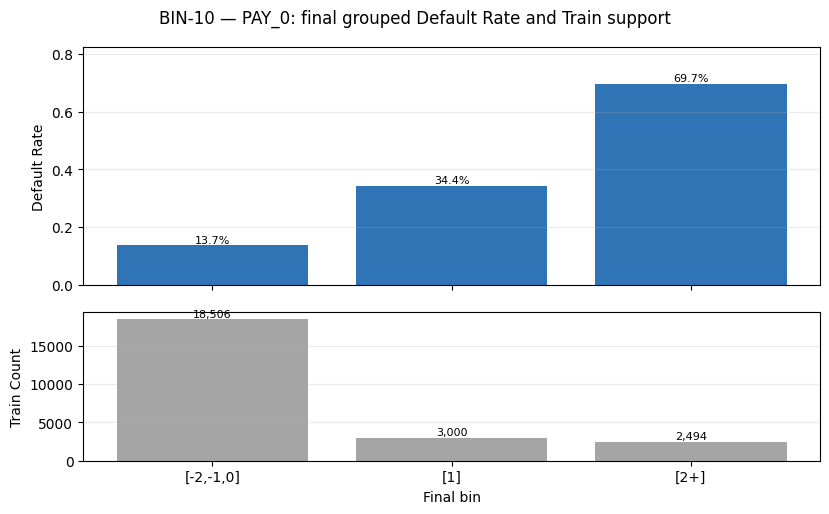

In [26]:
table=final_tables["PAY_0"]; labels=table["Final Bin"].astype(str).tolist(); x=np.arange(len(labels))
fig,axes=plt.subplots(2,1,figsize=(8.4,5.2),sharex=True,gridspec_kw={"height_ratios":[2.0,1.25]})
axes[0].bar(x,table["Default Rate"],color="#2F75B5"); axes[0].set_ylabel("Default Rate"); axes[0].set_ylim(0,min(1.0,max(.10,float(table["Default Rate"].max())*1.18))); axes[0].grid(axis="y",alpha=.25)
for i,v in enumerate(table["Default Rate"]): axes[0].text(i,v,f"{v:.1%}",ha="center",va="bottom",fontsize=8)
axes[1].bar(x,table["Count"],color="#A5A5A5"); axes[1].set_ylabel("Train Count"); axes[1].set_xlabel("Final bin"); axes[1].grid(axis="y",alpha=.25); axes[1].set_xticks(x,labels)
for i,v in enumerate(table["Count"]): axes[1].text(i,v,f"{int(v):,}",ha="center",va="bottom",fontsize=8)
fig.suptitle("BIN-10 — PAY_0: final grouped Default Rate and Train support",fontsize=12); fig.tight_layout(); plt.show(); plt.close(fig); figure_ids.append("BIN-10")


### BIN-11 — PAY_2 Final Grouping

- **Final grouping:** `[-2,-1,0,1] / [2] / [3+]`
- **Why approved:** Sparse code 1 joins low; code 2 remains separate; the sparse high tail is consolidated.
- **Observed result:** Default Rate rises and WOE falls across the frozen order.
- **Stage 4.4 note:** Variable retention, redundancy, and stability decisions are deferred; no Keep/Drop recommendation is made.


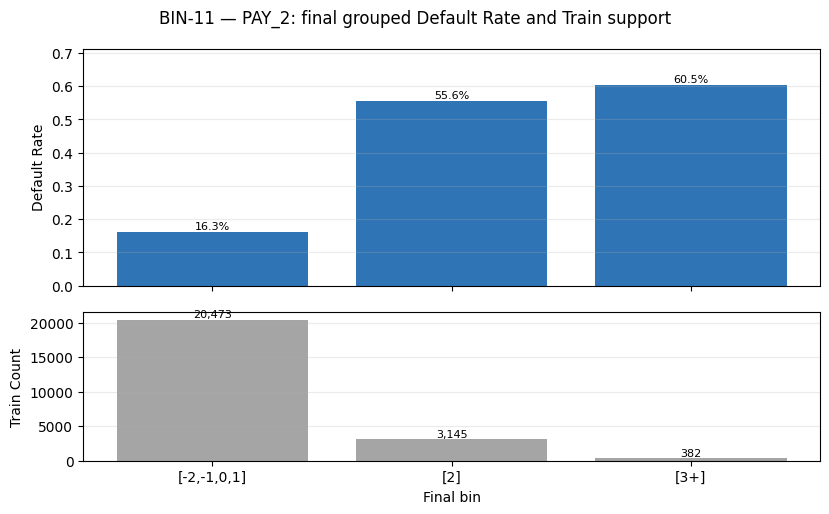

In [27]:
table=final_tables["PAY_2"]; labels=table["Final Bin"].astype(str).tolist(); x=np.arange(len(labels))
fig,axes=plt.subplots(2,1,figsize=(8.4,5.2),sharex=True,gridspec_kw={"height_ratios":[2.0,1.25]})
axes[0].bar(x,table["Default Rate"],color="#2F75B5"); axes[0].set_ylabel("Default Rate"); axes[0].set_ylim(0,min(1.0,max(.10,float(table["Default Rate"].max())*1.18))); axes[0].grid(axis="y",alpha=.25)
for i,v in enumerate(table["Default Rate"]): axes[0].text(i,v,f"{v:.1%}",ha="center",va="bottom",fontsize=8)
axes[1].bar(x,table["Count"],color="#A5A5A5"); axes[1].set_ylabel("Train Count"); axes[1].set_xlabel("Final bin"); axes[1].grid(axis="y",alpha=.25); axes[1].set_xticks(x,labels)
for i,v in enumerate(table["Count"]): axes[1].text(i,v,f"{int(v):,}",ha="center",va="bottom",fontsize=8)
fig.suptitle("BIN-11 — PAY_2: final grouped Default Rate and Train support",fontsize=12); fig.tight_layout(); plt.show(); plt.close(fig); figure_ids.append("BIN-11")


### BIN-12 — PAY_3 Final Grouping

- **Final grouping:** `[-2,-1,0,1] / [2] / [3+]`
- **Why approved:** Sparse code 1 joins low; code 2 remains separate; the sparse high tail is consolidated.
- **Observed result:** Default Rate rises and WOE falls across the frozen order.
- **Stage 4.4 note:** Variable retention, redundancy, and stability decisions are deferred; no Keep/Drop recommendation is made.


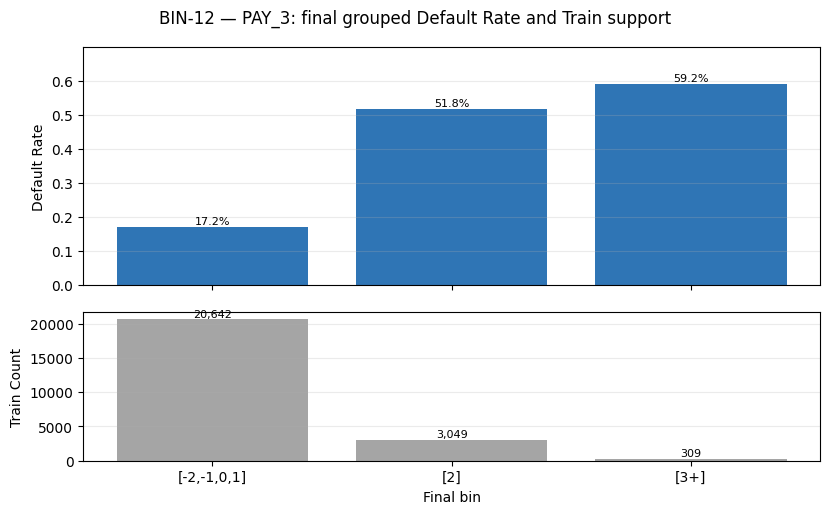

In [28]:
table=final_tables["PAY_3"]; labels=table["Final Bin"].astype(str).tolist(); x=np.arange(len(labels))
fig,axes=plt.subplots(2,1,figsize=(8.4,5.2),sharex=True,gridspec_kw={"height_ratios":[2.0,1.25]})
axes[0].bar(x,table["Default Rate"],color="#2F75B5"); axes[0].set_ylabel("Default Rate"); axes[0].set_ylim(0,min(1.0,max(.10,float(table["Default Rate"].max())*1.18))); axes[0].grid(axis="y",alpha=.25)
for i,v in enumerate(table["Default Rate"]): axes[0].text(i,v,f"{v:.1%}",ha="center",va="bottom",fontsize=8)
axes[1].bar(x,table["Count"],color="#A5A5A5"); axes[1].set_ylabel("Train Count"); axes[1].set_xlabel("Final bin"); axes[1].grid(axis="y",alpha=.25); axes[1].set_xticks(x,labels)
for i,v in enumerate(table["Count"]): axes[1].text(i,v,f"{int(v):,}",ha="center",va="bottom",fontsize=8)
fig.suptitle("BIN-12 — PAY_3: final grouped Default Rate and Train support",fontsize=12); fig.tight_layout(); plt.show(); plt.close(fig); figure_ids.append("BIN-12")


### BIN-13 — PAY_4 Final Grouping

- **Final grouping:** `[-2,-1,0,1] / [2] / [3+]`
- **Why approved:** Sparse code 1 joins low; code 2 remains separate; the sparse high tail is consolidated.
- **Observed result:** Default Rate rises and WOE falls across the frozen order.
- **Stage 4.4 note:** Variable retention, redundancy, and stability decisions are deferred; no Keep/Drop recommendation is made.


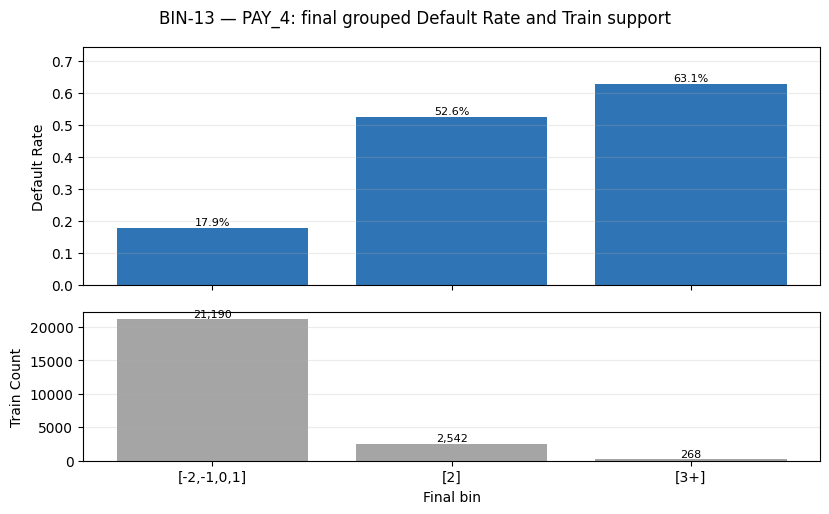

In [29]:
table=final_tables["PAY_4"]; labels=table["Final Bin"].astype(str).tolist(); x=np.arange(len(labels))
fig,axes=plt.subplots(2,1,figsize=(8.4,5.2),sharex=True,gridspec_kw={"height_ratios":[2.0,1.25]})
axes[0].bar(x,table["Default Rate"],color="#2F75B5"); axes[0].set_ylabel("Default Rate"); axes[0].set_ylim(0,min(1.0,max(.10,float(table["Default Rate"].max())*1.18))); axes[0].grid(axis="y",alpha=.25)
for i,v in enumerate(table["Default Rate"]): axes[0].text(i,v,f"{v:.1%}",ha="center",va="bottom",fontsize=8)
axes[1].bar(x,table["Count"],color="#A5A5A5"); axes[1].set_ylabel("Train Count"); axes[1].set_xlabel("Final bin"); axes[1].grid(axis="y",alpha=.25); axes[1].set_xticks(x,labels)
for i,v in enumerate(table["Count"]): axes[1].text(i,v,f"{int(v):,}",ha="center",va="bottom",fontsize=8)
fig.suptitle("BIN-13 — PAY_4: final grouped Default Rate and Train support",fontsize=12); fig.tight_layout(); plt.show(); plt.close(fig); figure_ids.append("BIN-13")


### BIN-14 — PAY_5 Final Grouping

- **Final grouping:** `[-2,-1,0,1] / [2] / [3+]`
- **Why approved:** Frozen domain completeness pre-maps unseen Train code 1 to low; tail consolidation resolves raw zero-event instability.
- **Observed result:** All observed final bins have finite WOE; code 1 was tested synthetically.
- **Stage 4.4 note:** Variable retention, redundancy, and stability decisions are deferred; no Keep/Drop recommendation is made.


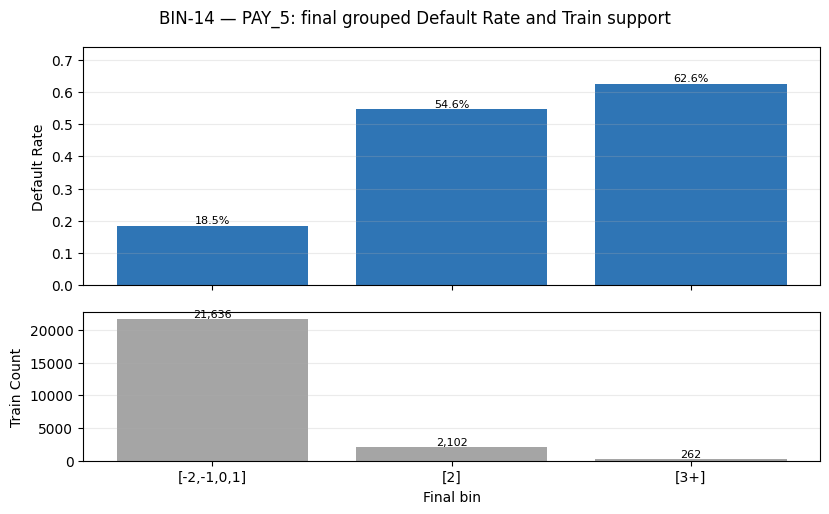

In [30]:
table=final_tables["PAY_5"]; labels=table["Final Bin"].astype(str).tolist(); x=np.arange(len(labels))
fig,axes=plt.subplots(2,1,figsize=(8.4,5.2),sharex=True,gridspec_kw={"height_ratios":[2.0,1.25]})
axes[0].bar(x,table["Default Rate"],color="#2F75B5"); axes[0].set_ylabel("Default Rate"); axes[0].set_ylim(0,min(1.0,max(.10,float(table["Default Rate"].max())*1.18))); axes[0].grid(axis="y",alpha=.25)
for i,v in enumerate(table["Default Rate"]): axes[0].text(i,v,f"{v:.1%}",ha="center",va="bottom",fontsize=8)
axes[1].bar(x,table["Count"],color="#A5A5A5"); axes[1].set_ylabel("Train Count"); axes[1].set_xlabel("Final bin"); axes[1].grid(axis="y",alpha=.25); axes[1].set_xticks(x,labels)
for i,v in enumerate(table["Count"]): axes[1].text(i,v,f"{int(v):,}",ha="center",va="bottom",fontsize=8)
fig.suptitle("BIN-14 — PAY_5: final grouped Default Rate and Train support",fontsize=12); fig.tight_layout(); plt.show(); plt.close(fig); figure_ids.append("BIN-14")


### BIN-15 — PAY_6 Final Grouping

- **Final grouping:** `[-2,-1,0,1] / [2] / [3+]`
- **Why approved:** Frozen domain completeness pre-maps unseen Train code 1 to low; tail consolidation resolves raw zero-event instability.
- **Observed result:** All observed final bins have finite WOE; code 1 was tested synthetically.
- **Stage 4.4 note:** Variable retention, redundancy, and stability decisions are deferred; no Keep/Drop recommendation is made.


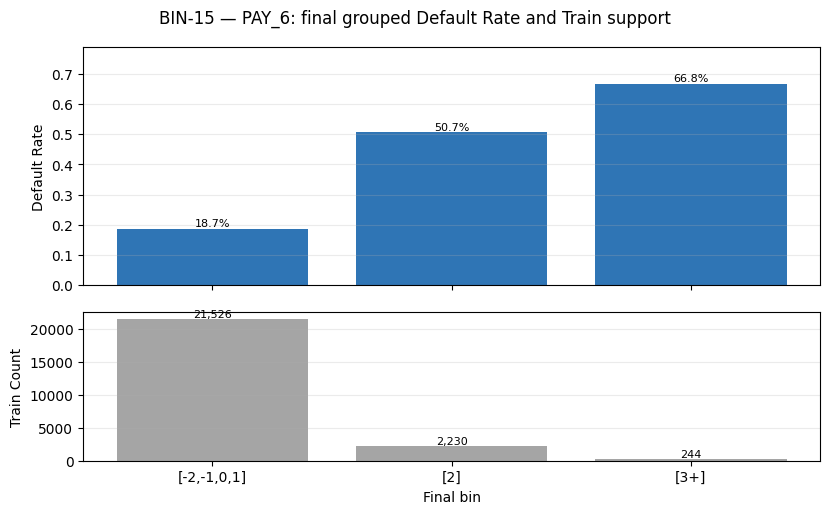

In [31]:
table=final_tables["PAY_6"]; labels=table["Final Bin"].astype(str).tolist(); x=np.arange(len(labels))
fig,axes=plt.subplots(2,1,figsize=(8.4,5.2),sharex=True,gridspec_kw={"height_ratios":[2.0,1.25]})
axes[0].bar(x,table["Default Rate"],color="#2F75B5"); axes[0].set_ylabel("Default Rate"); axes[0].set_ylim(0,min(1.0,max(.10,float(table["Default Rate"].max())*1.18))); axes[0].grid(axis="y",alpha=.25)
for i,v in enumerate(table["Default Rate"]): axes[0].text(i,v,f"{v:.1%}",ha="center",va="bottom",fontsize=8)
axes[1].bar(x,table["Count"],color="#A5A5A5"); axes[1].set_ylabel("Train Count"); axes[1].set_xlabel("Final bin"); axes[1].grid(axis="y",alpha=.25); axes[1].set_xticks(x,labels)
for i,v in enumerate(table["Count"]): axes[1].text(i,v,f"{int(v):,}",ha="center",va="bottom",fontsize=8)
fig.suptitle("BIN-15 — PAY_6: final grouped Default Rate and Train support",fontsize=12); fig.tight_layout(); plt.show(); plt.close(fig); figure_ids.append("BIN-15")


## 25. Final delinquency-summary tables and anchors

Approved persistence tails are structural thresholds. Rejected Train-specific `4-5 / 6` alternatives are not implemented.


In [32]:
summary_orders={"delinquent_months":DELINQUENT_MONTHS_BIN_ORDER,"max_delinquency":MAX_DELINQUENCY_BIN_ORDER,"severe_delinquent_months":SEVERE_DELINQUENT_MONTHS_BIN_ORDER}
for variable in DELINQUENCY_VARIABLES:
    table=register_final_table(variable,f"{variable}_BIN",summary_orders[variable]); print(f"{variable} — final grouped table"); display(table); print(f"{variable} — Final grouped total IV: {final_iv_totals[variable]:.12f}")
SUMMARY_ANCHORS={
"delinquent_months":{"bin":"4+","count":2064,"good":738,"bad":1326,"rate":.642442,"woe":-1.844617,"iv":.871421},
"max_delinquency":{"bin":"3+","count":939,"good":351,"bad":588,"rate":.626198,"woe":-1.774579,"iv":.794583},
"severe_delinquent_months":{"bin":"4+","count":1785,"good":596,"bad":1189,"rate":.666106,"woe":-1.949266,"iv":.846475}}
for variable,a in SUMMARY_ANCHORS.items():
    row=final_tables[variable].loc[final_tables[variable]["Final Bin"].astype(str)==a["bin"]].iloc[0]
    assert int(row["Count"])==a["count"] and int(row["Good"])==a["good"] and int(row["Bad"])==a["bad"]
    assert np.isclose(row["Default Rate"],a["rate"],atol=5e-7,rtol=0) and np.isclose(row["WOE"],a["woe"],atol=5e-7,rtol=0)
    assert np.isclose(final_iv_totals[variable],a["iv"],atol=5e-7,rtol=0)
print("PASS — all delinquency-tail exact counts and rounded anchors reproduced.")


delinquent_months — final grouped table


,Final Bin,Raw Values Included,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,0,0,15896,0.662333,14066,1830,0.115123,0.752555,0.344698,0.780806,0.318457
1,1,1,3572,0.148833,2502,1070,0.299552,0.133861,0.201545,-0.409207,0.027696
2,2,2,1532,0.063833,920,612,0.399478,0.049222,0.115276,-0.850997,0.056212
3,3,3,936,0.039000,465,471,0.503205,0.024878,0.088717,-1.271459,0.081169
4,4+,"4, 5, 6",2064,0.086000,738,1326,0.642442,0.039484,0.249765,-1.844617,0.387887


delinquent_months — Final grouped total IV: 0.871421079861
max_delinquency — final grouped table


,Final Bin,Raw Values Included,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,0,0,15896,0.662333,14066,1830,0.115123,0.752555,0.344698,0.780806,0.318457
1,1,1,1380,0.057500,1034,346,0.250725,0.055321,0.065172,-0.163887,0.001615
2,2,2,5785,0.241042,3240,2545,0.439931,0.173345,0.479375,-1.017196,0.311292
3,3+,"3, 4, 5, 6, 7, 8",939,0.039125,351,588,0.626198,0.018779,0.110755,-1.774579,0.163219


max_delinquency — Final grouped total IV: 0.794582506999
severe_delinquent_months — final grouped table


,Final Bin,Raw Values Included,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,0,0,17276,0.719833,15100,2176,0.125955,0.807875,0.409870,0.678568,0.270074
1,1,1,2799,0.116625,1887,912,0.325831,0.100958,0.171784,-0.531535,0.037647
2,2,2,1279,0.053292,708,571,0.446443,0.037879,0.107553,-1.043584,0.072711
3,3,3,861,0.035875,400,461,0.535424,0.021401,0.086834,-1.400572,0.091644
4,4+,"4, 5, 6",1785,0.074375,596,1189,0.666106,0.031887,0.223959,-1.949266,0.374400


severe_delinquent_months — Final grouped total IV: 0.846474512620
PASS — all delinquency-tail exact counts and rounded anchors reproduced.


## 26. Final delinquency-summary figures — BIN-16 through BIN-18

Fixed orders are used directly; these are diagnostics, not optimization or selection.


### BIN-16 — delinquent_months Final Grouping

- **Final grouping:** `0 / 1 / 2 / 3 / 4+`
- **Why approved:** 4+ means at least four of six months with PAY > 0, a stable persistence threshold rather than a local coincidence.
- **Observed result:** The grouped risk pattern remains strongly ordinal.
- **Stage 4.4 note:** Variable retention, redundancy, and stability decisions are deferred; no Keep/Drop recommendation is made.


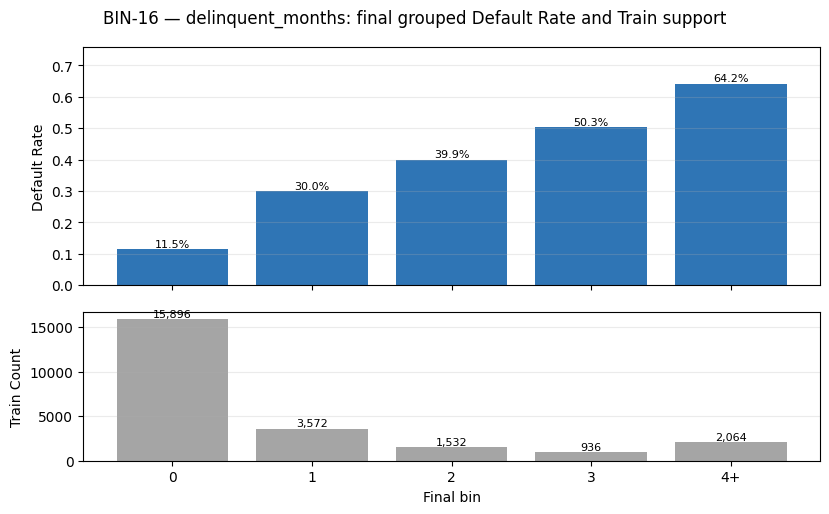

In [33]:
table=final_tables["delinquent_months"]; labels=table["Final Bin"].astype(str).tolist(); x=np.arange(len(labels))
fig,axes=plt.subplots(2,1,figsize=(8.4,5.2),sharex=True,gridspec_kw={"height_ratios":[2.0,1.25]})
axes[0].bar(x,table["Default Rate"],color="#2F75B5"); axes[0].set_ylabel("Default Rate"); axes[0].set_ylim(0,min(1.0,max(.10,float(table["Default Rate"].max())*1.18))); axes[0].grid(axis="y",alpha=.25)
for i,v in enumerate(table["Default Rate"]): axes[0].text(i,v,f"{v:.1%}",ha="center",va="bottom",fontsize=8)
axes[1].bar(x,table["Count"],color="#A5A5A5"); axes[1].set_ylabel("Train Count"); axes[1].set_xlabel("Final bin"); axes[1].grid(axis="y",alpha=.25); axes[1].set_xticks(x,labels)
for i,v in enumerate(table["Count"]): axes[1].text(i,v,f"{int(v):,}",ha="center",va="bottom",fontsize=8)
fig.suptitle("BIN-16 — delinquent_months: final grouped Default Rate and Train support",fontsize=12); fig.tight_layout(); plt.show(); plt.close(fig); figure_ids.append("BIN-16")


### BIN-17 — max_delinquency Final Grouping

- **Final grouping:** `0 / 1 / 2 / 3+`
- **Why approved:** Severity 3+ is an interpretable high-severity tail; individual high states are sparse and noisy.
- **Observed result:** The grouped risk pattern remains broadly ordered.
- **Stage 4.4 note:** Variable retention, redundancy, and stability decisions are deferred; no Keep/Drop recommendation is made.


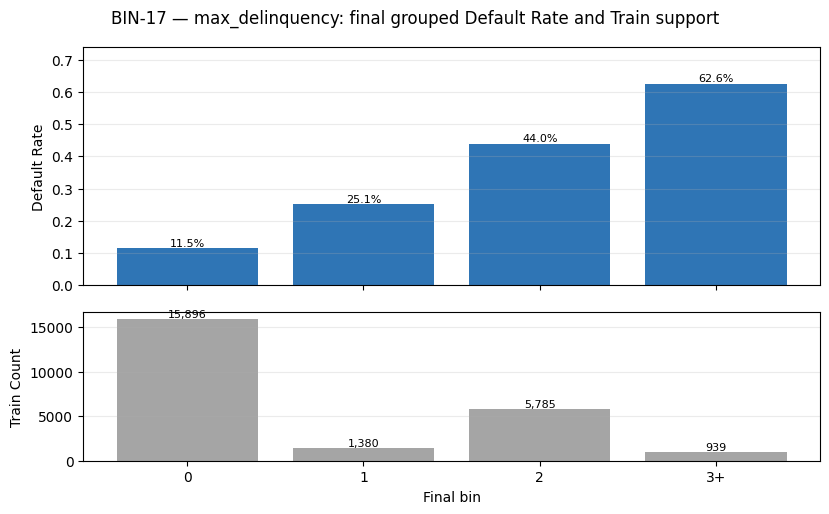

In [34]:
table=final_tables["max_delinquency"]; labels=table["Final Bin"].astype(str).tolist(); x=np.arange(len(labels))
fig,axes=plt.subplots(2,1,figsize=(8.4,5.2),sharex=True,gridspec_kw={"height_ratios":[2.0,1.25]})
axes[0].bar(x,table["Default Rate"],color="#2F75B5"); axes[0].set_ylabel("Default Rate"); axes[0].set_ylim(0,min(1.0,max(.10,float(table["Default Rate"].max())*1.18))); axes[0].grid(axis="y",alpha=.25)
for i,v in enumerate(table["Default Rate"]): axes[0].text(i,v,f"{v:.1%}",ha="center",va="bottom",fontsize=8)
axes[1].bar(x,table["Count"],color="#A5A5A5"); axes[1].set_ylabel("Train Count"); axes[1].set_xlabel("Final bin"); axes[1].grid(axis="y",alpha=.25); axes[1].set_xticks(x,labels)
for i,v in enumerate(table["Count"]): axes[1].text(i,v,f"{int(v):,}",ha="center",va="bottom",fontsize=8)
fig.suptitle("BIN-17 — max_delinquency: final grouped Default Rate and Train support",fontsize=12); fig.tight_layout(); plt.show(); plt.close(fig); figure_ids.append("BIN-17")


### BIN-18 — severe_delinquent_months Final Grouping

- **Final grouping:** `0 / 1 / 2 / 3 / 4+`
- **Why approved:** 4+ means at least four of six months with PAY ≥ 2, a structural repeated-severity threshold.
- **Observed result:** The grouped risk pattern remains strongly ordinal.
- **Stage 4.4 note:** Variable retention, redundancy, and stability decisions are deferred; no Keep/Drop recommendation is made.


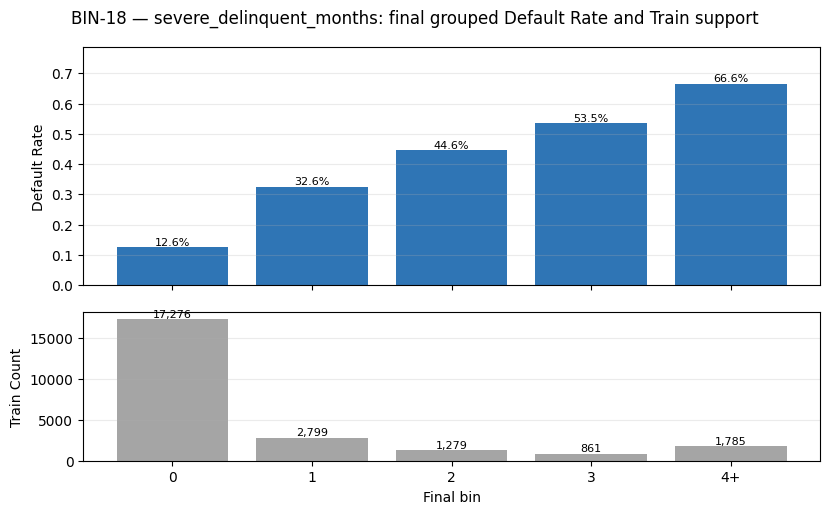

In [35]:
table=final_tables["severe_delinquent_months"]; labels=table["Final Bin"].astype(str).tolist(); x=np.arange(len(labels))
fig,axes=plt.subplots(2,1,figsize=(8.4,5.2),sharex=True,gridspec_kw={"height_ratios":[2.0,1.25]})
axes[0].bar(x,table["Default Rate"],color="#2F75B5"); axes[0].set_ylabel("Default Rate"); axes[0].set_ylim(0,min(1.0,max(.10,float(table["Default Rate"].max())*1.18))); axes[0].grid(axis="y",alpha=.25)
for i,v in enumerate(table["Default Rate"]): axes[0].text(i,v,f"{v:.1%}",ha="center",va="bottom",fontsize=8)
axes[1].bar(x,table["Count"],color="#A5A5A5"); axes[1].set_ylabel("Train Count"); axes[1].set_xlabel("Final bin"); axes[1].grid(axis="y",alpha=.25); axes[1].set_xticks(x,labels)
for i,v in enumerate(table["Count"]): axes[1].text(i,v,f"{int(v):,}",ha="center",va="bottom",fontsize=8)
fig.suptitle("BIN-18 — severe_delinquent_months: final grouped Default Rate and Train support",fontsize=12); fig.tight_layout(); plt.show(); plt.close(fig); figure_ids.append("BIN-18")


## 27. Frozen categorical confirmation and final tables

No category is renamed, merged, or dropped. Sparse `Other / Unknown` groups stay separate; stability and selection are deferred.


In [36]:
assert sorted(train_work["SEX"].unique().tolist())==sex_order==[1,2]
assert set(train_work["EDUCATION_GROUP"].unique())==set(EDUCATION_ORDER)
assert set(train_work["MARRIAGE_GROUP"].unique())==set(MARRIAGE_ORDER)
assert int((train_work["EDUCATION_GROUP"]=="Other / Unknown").sum())==386
assert int((train_work["MARRIAGE_GROUP"]=="Other / Unknown").sum())==302
for variable,order in {"SEX":sex_order,"EDUCATION_GROUP":EDUCATION_ORDER,"MARRIAGE_GROUP":MARRIAGE_ORDER}.items():
    table=register_final_table(variable,variable,order); print(f"{variable} — unchanged-category final table"); display(table); print(f"{variable} — Final grouped total IV: {final_iv_totals[variable]:.12f}")
print("PASS — SEX, EDUCATION_GROUP, and MARRIAGE_GROUP category sets and counts preserved.")
print("Sparse evidence: EDUCATION Other / Unknown=386; MARRIAGE Other / Unknown=302.")


SEX — unchanged-category final table


,Final Bin,Raw Values Included,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,1,1 (unchanged),9486,0.395250,7174,2312,0.243728,0.383821,0.435487,-0.126288,0.006525
1,2,2 (unchanged),14514,0.604750,11517,2997,0.206490,0.616179,0.564513,0.087574,0.004525


SEX — Final grouped total IV: 0.011049354693
EDUCATION_GROUP — unchanged-category final table


,Final Bin,Raw Values Included,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,Graduate School,Graduate School (unchanged),8455,0.352292,6824,1631,0.192904,0.365096,0.307214,0.172614,0.009991
1,University,University (unchanged),11256,0.469000,8582,2674,0.237562,0.459151,0.503673,-0.092547,0.004120
2,High School,High School (unchanged),3903,0.162625,2927,976,0.250064,0.156599,0.183839,-0.160368,0.004368
3,Other / Unknown,Other / Unknown (unchanged),386,0.016083,358,28,0.072539,0.019154,0.005274,1.289690,0.017900


EDUCATION_GROUP — Final grouped total IV: 0.036380079009
MARRIAGE_GROUP — unchanged-category final table


,Final Bin,Raw Values Included,Count,% Train,Good,Bad,Default Rate,Dist Good,Dist Bad,WOE,IV Contribution
0,Married,Married (unchanged),10892,0.453833,8354,2538,0.233015,0.446953,0.478056,-0.067275,0.002092
1,Single,Single (unchanged),12806,0.533583,10112,2694,0.210370,0.541009,0.507440,0.064057,0.002150
2,Other / Unknown,Other / Unknown (unchanged),302,0.012583,225,77,0.254967,0.012038,0.014504,-0.186344,0.000459


MARRIAGE_GROUP — Final grouped total IV: 0.004702252234
PASS — SEX, EDUCATION_GROUP, and MARRIAGE_GROUP category sets and counts preserved.
Sparse evidence: EDUCATION Other / Unknown=386; MARRIAGE Other / Unknown=302.


## 28. Final monotonicity diagnostics

For nine ordinal predictors, ordered Default Rate and WOE are checked diagnostically. Frozen bins are not reordered, merged, searched, or selected.


In [37]:
monotonicity_tables={}; monotonicity_summary_rows=[]
for variable in PAY_VARIABLES+DELINQUENCY_VARIABLES:
    table=final_tables[variable][["Final Bin","Default Rate","WOE"]].copy(); rd=table["Default Rate"].diff(); wd=table["WOE"].diff()
    table["Default Rate direction check"]=["start"]+["non-decreasing" if v>=-1e-12 else "local decrease retained" for v in rd.iloc[1:]]
    table["WOE direction check"]=["start"]+["non-increasing" if v<=1e-12 else "local increase retained" for v in wd.iloc[1:]]
    broad=bool((rd.iloc[1:]>=-1e-12).all() and (wd.iloc[1:]<=1e-12).all()); monotonicity_tables[variable]=table
    monotonicity_summary_rows.append({"Variable":variable,"Broad frozen-bin ordering":"PASS" if broad else "LOCAL IMPERFECTION RETAINED"})
    print(f"{variable} — ordered Default Rate / WOE diagnostic"); display(table)
monotonicity_summary=pd.DataFrame(monotonicity_summary_rows); display(monotonicity_summary)
print("Diagnostic only — frozen grouping unchanged.")


PAY_0 — ordered Default Rate / WOE diagnostic


,Final Bin,Default Rate,WOE,Default Rate direction check,WOE direction check
0,"[-2,-1,0]",0.137253,0.579659,start,start
1,[1],0.343667,-0.611642,non-decreasing,non-increasing
2,[2+],0.696872,-2.091088,non-decreasing,non-increasing


PAY_2 — ordered Default Rate / WOE diagnostic


,Final Bin,Default Rate,WOE,Default Rate direction check,WOE direction check
0,"[-2,-1,0,1]",0.162604,0.380338,start,start
1,[2],0.556121,-1.484072,non-decreasing,non-increasing
2,[3+],0.604712,-1.683777,non-decreasing,non-increasing


PAY_3 — ordered Default Rate / WOE diagnostic


...

,Final Bin,Default Rate,WOE,Default Rate direction check,WOE direction check
0,0,0.115123,0.780806,start,start
1,1,0.250725,-0.163887,non-decreasing,non-increasing
2,2,0.439931,-1.017196,non-decreasing,non-increasing
3,3+,0.626198,-1.774579,non-decreasing,non-increasing


severe_delinquent_months — ordered Default Rate / WOE diagnostic


,Final Bin,Default Rate,WOE,Default Rate direction check,WOE direction check
0,0,0.125955,0.678568,start,start
1,1,0.325831,-0.531535,non-decreasing,non-increasing
2,2,0.446443,-1.043584,non-decreasing,non-increasing
3,3,0.535424,-1.400572,non-decreasing,non-increasing
4,4+,0.666106,-1.949266,non-decreasing,non-increasing


,Variable,Broad frozen-bin ordering
0,PAY_0,PASS
1,PAY_2,PASS
2,PAY_3,PASS
3,PAY_4,PASS
4,PAY_5,PASS
5,PAY_6,PASS
6,delinquent_months,PASS
7,max_delinquency,PASS
8,severe_delinquent_months,PASS


Diagnostic only — frozen grouping unchanged.


## 29. Final reconciliation and Stage 4.2 completion boundary

All 12 remain candidates. This closes Codex implementation only; it does not claim Reviewer PASS or a milestone commit.


In [38]:
assert list(final_tables)==SCOPE_VARIABLES and len(final_tables)==12 and len(final_iv_totals)==12
assert all(int(t["Count"].sum())==24000 and int(t["Good"].sum())==18691 and int(t["Bad"].sum())==5309 for t in final_tables.values())
assert all((t["Good"]>0).all() and (t["Bad"]>0).all() for t in final_tables.values())
assert all(np.isfinite(t["WOE"]).all() and np.isfinite(t["IV Contribution"]).all() for t in final_tables.values())
assert all(np.isfinite(v) for v in final_iv_totals.values()) and not SMOOTHING_USED_IN_FINAL_TABLES
assert figure_ids==[f"BIN-{n:02d}" for n in range(1,19)] and len(set(figure_ids))==18
assert TEST_SEAL_STATUS.startswith("SEALED") and len(train_work)==24000
assert train_work[ID_COL].equals(phase_b_id_before) and train_work[TARGET].equals(phase_b_target_before)
pd.testing.assert_frame_equal(train_work[PAY_VARIABLES],phase_b_pay_before,check_exact=True)
pd.testing.assert_frame_equal(train_work[DELINQUENCY_VARIABLES],phase_b_summary_before,check_exact=True)
FINAL_BINNING_PERFORMED=True; SMOOTHING_PERFORMED=False; VARIABLE_SELECTION_PERFORMED=False; CONTINUOUS_BINNING_PERFORMED=False; MODELING_PERFORMED=False; KFOLD_EXECUTED=False; TEST_TARGET_ANALYZED=False
assert FINAL_BINNING_PERFORMED and not any([SMOOTHING_PERFORMED,VARIABLE_SELECTION_PERFORMED,CONTINUOUS_BINNING_PERFORMED,MODELING_PERFORMED,KFOLD_EXECUTED,TEST_TARGET_ANALYZED])
iv_summary_fixed_order=pd.DataFrame({"Variable":SCOPE_VARIABLES,"Final grouped total IV":[final_iv_totals[v] for v in SCOPE_VARIABLES]}); display(iv_summary_fixed_order)
display(pd.DataFrame({"Result":["PASS — exactly 12 final grouped tables","PASS — 24,000 / 18,691 / 5,309 reconciled for every table","PASS — no final Good=0 or Bad=0","PASS — all final WOE/IV finite","PASS — no smoothing","PASS — BIN-10 through BIN-18 present once each","PASS — Holdout remained deleted and sealed","PASS — no selection, continuous binning, model, KFold, AUC, or KS","AWAITING — final Stage 4.2 Reviewer validation"]},index=["Final tables","Counts","Zero-event resolution","Finite WOE/IV","Smoothing","Figures","Holdout","Scope exclusions","Next gate"]))
print("Stage 4.2B implementation complete — awaiting final Stage 4.2 Reviewer validation.")


,Variable,Final grouped total IV
0,PAY_0,0.872146
1,PAY_2,0.548099
2,PAY_3,0.414434
3,PAY_4,0.359543
4,PAY_5,0.327106
5,PAY_6,0.288166
6,delinquent_months,0.871421
7,max_delinquency,0.794583
8,severe_delinquent_months,0.846475
9,SEX,0.011049


,Result
Final tables,PASS — exactly 12 final grouped tables
Counts,"PASS — 24,000 / 18,691 / 5,309 reconciled for ..."
Zero-event resolution,PASS — no final Good=0 or Bad=0
Finite WOE/IV,PASS — all final WOE/IV finite
Smoothing,PASS — no smoothing
Figures,PASS — BIN-10 through BIN-18 present once each
Holdout,PASS — Holdout remained deleted and sealed
Scope exclusions,"PASS — no selection, continuous binning, model..."
Next gate,AWAITING — final Stage 4.2 Reviewer validation


Stage 4.2B implementation complete — awaiting final Stage 4.2 Reviewer validation.
